# 117 · why `freqcls-bandproj-v1` falls short of the ref
Three src9 `transformer2` runs, 200 ep, same data, recipe, seed and size (34.9M), differing only in how each laser's 18 band tokens become one token:

| key | run | before attention | 18 band tokens → 1 laser token | ID IoU@.08 | OOD |
|---|---|---|---|---|---|
| `ref` | `s9-t2-ref-vase-200` | one shared `W_x` (130→128) | 2 blocks, then ~uniform gate + **flatten + Linear(2304→128)** = Σ_b W_b h_b (18 untied 128×128 **after** attention) | .679 | .377 |
| `freqcls` | `s9-t2-freqcls-vase-200` | one shared `W_x` | 2 blocks with a `[cls]` token; its output | .561 | .309 |
| `bandproj` | `freqcls-bandproj-v1` | **18 untied `W_x^b`** (130→128) | 2 blocks with a `[cls]` token; its output | .606 | .344 |

Laser stage, flatten (12,800→1024) and decoder are identical. ID = per-sample pooled over the one-object + two-object splits; OOD = rotated / cylinder /
unseen-object / unseen-speaker / unseen-laser / lid (nb113). nb115/nb116 showed `freq_cls` folds the bands (shared V + flat attention).
`band_proj` puts band identity back on the **linear** input. The hypothesis tested here: the blocks compute **nonlinear** per-band features,
and the `[cls]` still pools those through one shared V, so their band identity is lost again. The ref keeps it with its untied W_b *after* attention.

Sections: **A** under-fit or over-fit, and would more epochs help · **B** where the gap is (splits, CoM vs shape, objects, positions, sizes,
under/over-painting) · **C** mechanism inside the freq encoder · **D** band occlusion · **E** ranked fixes. fp32 on the GPU, ≤ 6 GB CPU RAM.

In [1]:
import os, sys, math, re
os.environ["TQDM_DISABLE"] = "1"
from pathlib import Path
import numpy as np, pandas as pd, torch, torch.nn.functional as F
import matplotlib.pyplot as plt
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src9").exists()), Path.home() / "workspace/good-vibrations")
sys.path.insert(0, str(ROOT / "src9")); os.chdir(ROOT)
import dataset as D9, score
from arch.transformer2 import Transformer2
torch.set_num_threads(8); torch.manual_seed(0); np.random.seed(0)
DEV = "cuda" if torch.cuda.is_available() else "cpu"
torch.backends.cuda.matmul.allow_tf32 = False; torch.backends.cudnn.allow_tf32 = False   # fp32 for analysis
plt.rcParams.update({"figure.dpi": 90, "font.size": 10})
RUNS = {"ref": "s9-t2-ref-vase-200", "freqcls": "s9-t2-freqcls-vase-200", "bandproj": "freqcls-bandproj-v1"}
FLAGS = {"ref": dict(freq_cls=0), "freqcls": dict(freq_cls=1), "bandproj": dict(freq_cls=1, band_proj=1), "freqcls8": dict(freq_cls=1, freq_layers=8)}
RUN_DIR = {**RUNS, "freqcls8": "s9-t2-freqcls8-vase-200"}   # freqcls8 stopped at ep150: only the ep100 checkpoint exists
COL = {"ref": "tab:green", "freqcls": "tab:orange", "bandproj": "tab:purple", "freqcls8": "tab:brown", "ref-1k": "darkgreen", "cls-1k": "tab:red"}
CAT = {(b, s): c for b, cs in D9.CATEGORIES.items() for c, ss in cs.items() for s in ss}
ID_CATS, OOD_CATS = {"id", "multiple"}, {"rotated", "cylinder", "unseen-object", "unseen-speaker", "unseen-laser", "lid"}
THR = 0.08
print("device", DEV)

device cuda


## A · under-fitting or generalizing worse?
Per-sample eval outputs are saved every 50 ep, so ID / OOD at 50 / 100 / 150 / 200 come from `outputs_history` (same per-sample scoring as nb113).
The per-sample table also keeps true / predicted area, CoM, precision and recall for section B. Train IoU in eval mode (no aug) is logged only
once, at the end; the ep100 point is computed below by a forward pass on 300 train samples (section C loads them).

In [2]:
def com_of(m):
    r, c = np.nonzero(m); return (r.mean() / m.shape[0], c.mean() / m.shape[1]) if len(r) else (np.nan, np.nan)

def shift_to(b, dr, dc):
    """roll a bool mask by (dr, dc) pixels, no wrap-around"""
    out = np.zeros_like(b); H, W = b.shape
    r0, r1, c0, c1 = max(dr, 0), H + min(dr, 0), max(dc, 0), W + min(dc, 0)
    out[r0:r1, c0:c1] = b[r0 - dr:r1 - dr, c0 - dc:c1 - dc]; return out

META = {}
def meta_of(exp, sid, pos, spk):
    k = (exp, sid, pos, spk)
    if k not in META: m = D9.load_meta(score.sample_dir(exp, sid, pos, spk)); META[k] = ("+".join(sorted(m["objects"])), m["n_objects"])
    return META[k]

def per_sample(run, ep):
    rows = []
    for f in sorted((ROOT / "runs" / run / "outputs_history/eval").glob(f"*/*/ep{ep:04d}-ba*.pt")):
        d = torch.load(f, weights_only=False, map_location="cpu"); p, info = d["mask_pred"].float().numpy(), d["info"]
        bx, sp = f.parent.parent.name, f.parent.name
        for i in range(len(p)):
            k = (info["experiment"][i], info["sample_id"][i], int(info["position_id"][i]), int(info["speaker"][i]))
            y = score.truth(*k, 64, 64) > .5
            if not y.any(): continue
            b = p[i] > THR; inter = (b & y).sum()
            tc, pc = com_of(y), com_of(b)
            # shape-only IoU: move the prediction so its CoM sits on the true CoM, then score
            sh = (b & y).sum() / max((b | y).sum(), 1) if np.isnan(pc[0]) else (lambda bb: (bb & y).sum() / max((bb | y).sum(), 1))(shift_to(b, round((tc[0] - pc[0]) * 64), round((tc[1] - pc[1]) * 64)))
            obj, nobj = meta_of(*k)
            rows.append(dict(box=bx, split=sp, category=CAT.get((bx, sp)), key=k, object=obj, n_obj=nobj, iou=inter / max((b | y).sum(), 1),
                             area_true=y.sum(), area_pred=b.sum(), recall=inter / y.sum(), precision=inter / max(b.sum(), 1), miss=float(inter == 0),
                             com_r=tc[0], com_c=tc[1], com_err=np.hypot(tc[0] - pc[0], tc[1] - pc[1]), shape_iou=sh))
    return pd.DataFrame(rows)

EPS = [50, 100, 150, 200]
PS = {(r, ep): per_sample(RUNS[r], ep) for r in RUNS for ep in EPS}
idood = lambda df: (df[df.category.isin(ID_CATS)].iou.mean(), df[df.category.isin(OOD_CATS)].iou.mean())
print({r: [tuple(round(v, 3) for v in idood(PS[r, ep])) for ep in EPS] for r in RUNS})

{'ref': [(np.float64(0.283), np.float64(0.177)), (np.float64(0.597), np.float64(0.354)), (np.float64(0.67), np.float64(0.373)), (np.float64(0.679), np.float64(0.377))], 'freqcls': [(np.float64(0.066), np.float64(0.053)), (np.float64(0.409), np.float64(0.23)), (np.float64(0.531), np.float64(0.293)), (np.float64(0.562), np.float64(0.309))], 'bandproj': [(np.float64(0.152), np.float64(0.099)), (np.float64(0.456), np.float64(0.281)), (np.float64(0.57), np.float64(0.334)), (np.float64(0.606), np.float64(0.344))]}


Context runs (no checkpoints needed): `freqcls8` (8 freq blocks, stopped at ep150), and the two **1000-ep schedules** `s9-t2-ref-vase-1k` and
`s9-t2-cls-vase-1k` (freq_cls + laser_cls, with a LayerNorm): the only [cls] run trained long. Their ID curves say how much a 5× longer
schedule buys a `[cls]` model vs the ref.

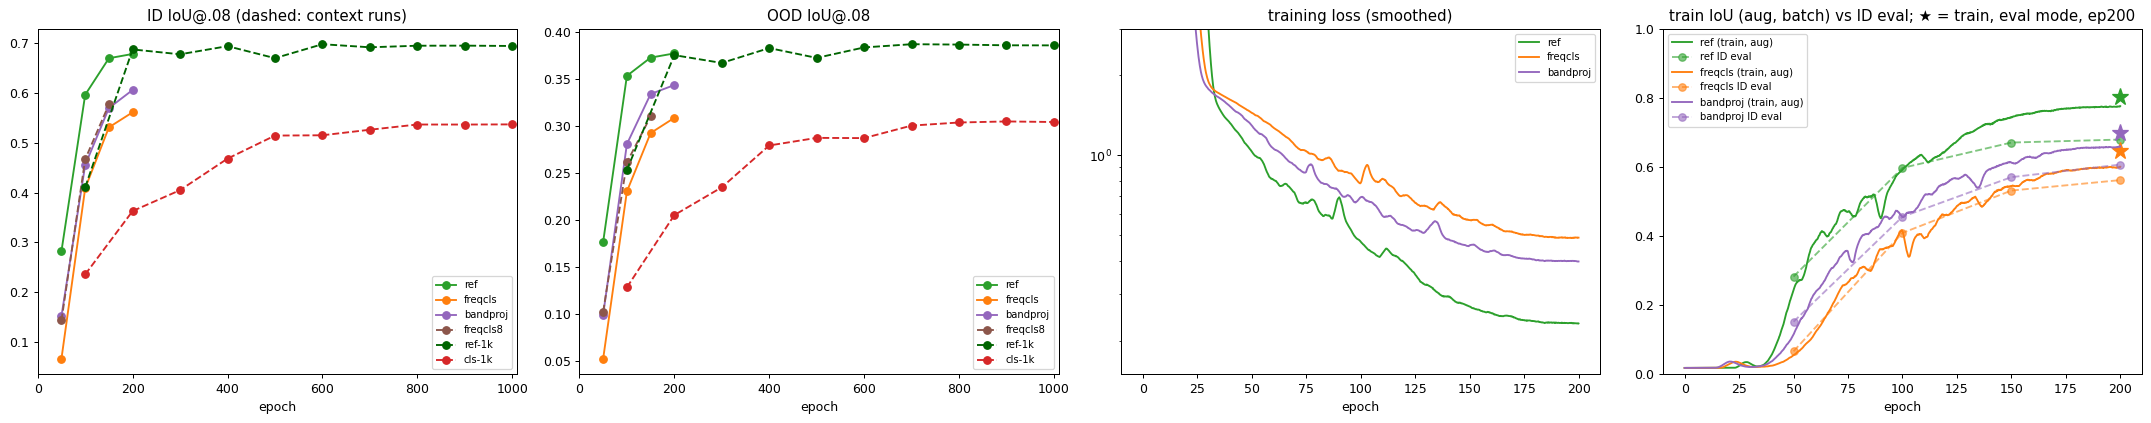

,ID@50,ID@100,ID@150,ID@200,OOD@50,OOD@100,OOD@150,OOD@200,train_IoU_eval@200,train−ID@200,loss_last100,mask_bce_last100,ΔID 150→200
ref,0.283,0.597,0.670,0.679,0.177,0.354,0.373,0.377,0.803,0.124,0.234,0.011,0.009
freqcls,0.066,0.409,0.531,0.562,0.053,0.230,0.293,0.309,0.644,0.083,0.490,0.026,0.030
bandproj,0.152,0.456,0.570,0.606,0.099,0.281,0.334,0.344,0.698,0.092,0.400,0.018,0.036


1k schedules, ID at ep 200 / 500 / 1000: {'ref-1k': [np.float64(0.688), np.float64(0.67), np.float64(0.695)], 'cls-1k': [np.float64(0.363), np.float64(0.515), np.float64(0.537)]}


In [3]:
CTX = {"freqcls8": ("s9-t2-freqcls8-vase-200", [50, 100, 150]), "ref-1k": ("s9-t2-ref-vase-1k", list(range(100, 1001, 100))),
       "cls-1k": ("s9-t2-cls-vase-1k", list(range(100, 1001, 100)))}
CURVE = {r: [(ep, *idood(PS[r, ep])) for ep in EPS] for r in RUNS}
for k, (run, eps) in CTX.items(): CURVE[k] = [(ep, *idood(per_sample(run, ep))) for ep in eps]

def logs(run):
    txt = (ROOT / "runs" / run / "logs-rank0.txt").read_text()
    ser = lambda k: pd.Series({int(b): float(v) for b, v in re.findall(rf"^\[metric\]\[batch=(\d+)\]: {re.escape(k)}: ([0-9.eE+-]+)", txt, re.M)}).sort_index()
    return dict(loss=ser("loss/train/total"), mask=ser("loss/train/mask"), iou_aug=ser("metrics/train/iou08"),
                train_iou=float(re.findall(r"Eval metrics/train/iou08: ([0-9.]+)", txt)[-1]) if "Eval metrics/train/iou08" in txt else np.nan)
LOG = {r: logs(RUNS[r]) for r in RUNS}
fig, axs = plt.subplots(1, 4, figsize=(24, 4.8))
for r, cv in CURVE.items():
    e, i, o = zip(*cv); ls = "--" if r in CTX else "-"
    axs[0].plot(e, i, "o" + ls, color=COL[r], label=r); axs[1].plot(e, o, "o" + ls, color=COL[r], label=r)
for r in RUNS:
    L = LOG[r]
    axs[2].plot(L["loss"].index / 10, L["loss"].rolling(30, min_periods=1).mean(), color=COL[r], label=r)
    axs[3].plot(L["iou_aug"].index / 10, L["iou_aug"].rolling(30, min_periods=1).mean(), color=COL[r], label=f"{r} (train, aug)")
    e, i, _ = zip(*CURVE[r]); axs[3].plot(e, i, "o--", color=COL[r], alpha=.6, label=f"{r} ID eval")
    axs[3].plot(200, L["train_iou"], "*", ms=14, color=COL[r])
axs[0].set(title="ID IoU@.08 (dashed: context runs)", xlabel="epoch", xlim=(0, 1010)); axs[1].set(title="OOD IoU@.08", xlabel="epoch", xlim=(0, 1010))
axs[2].set(title="training loss (smoothed)", xlabel="epoch", yscale="log", ylim=(0.15, 3)); axs[3].set(title="train IoU (aug, batch) vs ID eval; ★ = train, eval mode, ep200", xlabel="epoch", ylim=(0, 1))
for ax in axs: ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
tab = pd.DataFrame({r: dict(**{f"ID@{e}": i for e, i, _ in CURVE[r]}, **{f"OOD@{e}": o for e, _, o in CURVE[r]}) for r in RUNS}).T
for r in RUNS:
    tab.loc[r, "train_IoU_eval@200"] = LOG[r]["train_iou"]; tab.loc[r, "train−ID@200"] = LOG[r]["train_iou"] - tab.loc[r, "ID@200"]
    tab.loc[r, "loss_last100"] = LOG[r]["loss"].iloc[-100:].mean(); tab.loc[r, "mask_bce_last100"] = LOG[r]["mask"].iloc[-100:].mean()
    tab.loc[r, "ΔID 150→200"] = tab.loc[r, "ID@200"] - tab.loc[r, "ID@150"]
display(tab.round(3))
c1 = {k: dict(CURVE[k] and {e: i for e, i, _ in CURVE[k]}) for k in ["ref-1k", "cls-1k"]}
print("1k schedules, ID at ep 200 / 500 / 1000:", {k: [round(c1[k][e], 3) for e in (200, 500, 1000)] for k in c1})

**A · reading.** It is mostly **under-fitting**, not worse generalization. bandproj fits the *training* set less well than ref (train IoU in eval mode
.698 vs .803, train loss .40 vs .23, mask BCE .018 vs .011). Its train − ID gap is *smaller* (.092 vs .124), so the eval deficit (.073 ID) is smaller
than the train deficit (.105). It is **still climbing** at ep200: +.036 ID from ep150 to 200, vs +.009 for ref, which has plateaued (ref-1k gains only
+.016 more over 800 extra epochs: .679 → .695). The only long [cls] run (cls-1k, freq_cls + laser_cls) went .363 → .515 → .537 at ep 200 / 500 / 1000
and halved its gap to ref-1k (.325 → .158) but still plateaued well below it. For bandproj, by analogy: a 500–1000 ep schedule plausibly buys
+.02–.04 ID, so the gap shrinks to roughly .03–.05 but does not close. More epochs help, and on their own they are not enough.

## B · where is the gap?
All at ep200, per sample. Splits with no category (`control`, `unseen-angle`, `broken`, `unseen-rotated-object`) are shown too. `gap` = ref − bandproj.
`share of ID/OOD gap` = how much of the pooled ID (or OOD) deficit each split accounts for (split n × its gap / pooled n).

In [4]:
E = {r: PS[r, 200].copy() for r in RUNS}
for r in RUNS: assert (E[r].key.values == E["ref"].key.values).all()               # same samples, same order -> paired comparisons
S = pd.DataFrame({"box": E["ref"].box, "split": E["ref"].split, "category": E["ref"].category.fillna("other"), "n": 1})
for r in RUNS: S[r] = E[r].iou.values
sp = S.groupby(["box", "split", "category"]).agg(n=("n", "sum"), **{r: (r, "mean") for r in RUNS}).reset_index()
sp["gap"] = sp.ref - sp.bandproj; sp["bandproj−freqcls"] = sp.bandproj - sp.freqcls
nid, nood = S.category.isin(ID_CATS).sum(), S.category.isin(OOD_CATS).sum()
sp["share_of_ID_gap"] = np.where(sp.category.isin(ID_CATS), sp.n * sp.gap / nid, np.nan) / (idood(E["ref"])[0] - idood(E["bandproj"])[0])
sp["share_of_OOD_gap"] = np.where(sp.category.isin(OOD_CATS), sp.n * sp.gap / nood, np.nan) / (idood(E["ref"])[1] - idood(E["bandproj"])[1])
pd.set_option("display.max_rows", 120); pd.set_option("display.width", 250)
display(sp.sort_values("gap", ascending=False).round(3))
cat = S.groupby("category")[list(RUNS)].mean(); cat["gap"] = cat.ref - cat.bandproj; cat["n"] = S.groupby("category").size()
display(cat.sort_values("gap", ascending=False).round(3))

,box,split,category,n,ref,freqcls,bandproj,gap,bandproj−freqcls,share_of_ID_gap,share_of_OOD_gap
4,cardboard,cube-rotated,rotated,20,0.543,0.269,0.368,0.175,0.099,NaN,0.074
33,gastro,cube-vase,multiple,27,0.373,0.209,0.234,0.139,0.025,0.021,NaN
31,gastro,cube-unseen-speaker-baseline,control,105,0.614,0.455,0.476,0.138,0.021,NaN,NaN
41,gastro,two-cubes,multiple,42,0.349,0.159,0.212,0.137,0.053,0.032,NaN
42,gastro,unseen-position,unseen-position,77,0.716,0.550,0.591,0.125,0.041,NaN,NaN
10,cardboard,glass-cup,control,12,0.547,0.409,0.425,0.121,0.016,NaN,NaN
21,cardboard,vase-laser-shifted-2,unseen-laser,36,0.355,0.222,0.234,0.121,0.012,NaN,0.092
17,cardboard,tomato-sauce,unseen-object,35,0.681,0.475,0.572,0.109,0.097,NaN,0.080
14,cardboard,soap-dispenser,id,215,0.676,0.525,0.573,0.103,0.048,0.123,NaN
52,plastic,cube-vase,multiple,32,0.463,0.366,0.362,0.102,-0.004,0.018,NaN


,ref,freqcls,bandproj,gap,n
category,,,,,
multiple,0.393,0.253,0.310,0.083,310
control,0.604,0.473,0.528,0.076,399
id,0.719,0.605,0.648,0.071,2191
unseen-angle,0.530,0.427,0.465,0.065,108
unseen-position,0.644,0.537,0.582,0.063,197
unseen-speaker,0.372,0.268,0.317,0.056,85
rotated,0.552,0.419,0.505,0.048,166
unseen-object,0.578,0.501,0.540,0.038,550
broken,0.390,0.221,0.365,0.026,12


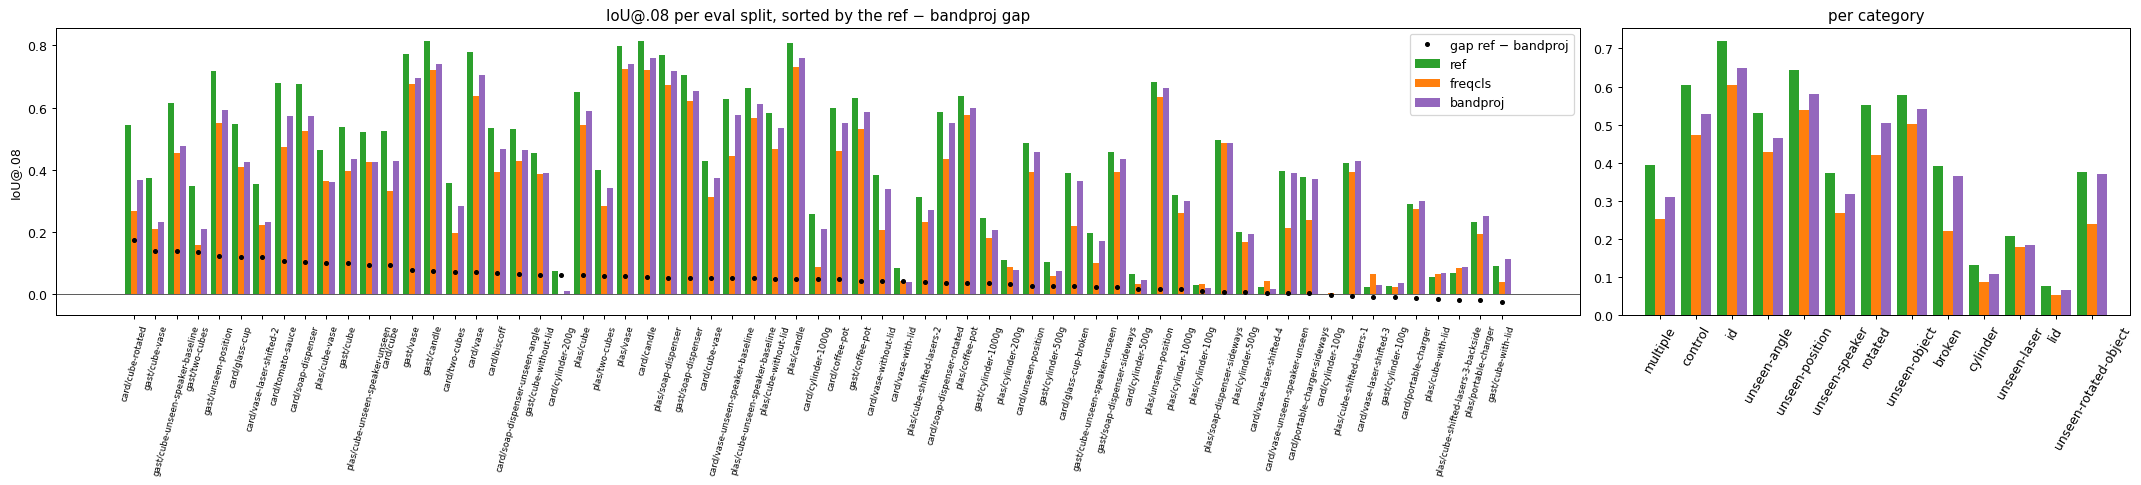

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(24, 5.5), gridspec_kw=dict(width_ratios=[3, 1]))
o = sp.sort_values("gap", ascending=False).reset_index(drop=True); x = np.arange(len(o)); w = .28
for i, r in enumerate(RUNS): axs[0].bar(x + (i - 1) * w, o[r], w, color=COL[r], label=r)
axs[0].plot(x, o.gap, "k.", label="gap ref − bandproj")
axs[0].set_xticks(x, [f"{b[:4]}/{s}" for b, s in zip(o.box, o.split)], rotation=75, fontsize=7); axs[0].axhline(0, color="k", lw=.5)
axs[0].set(title="IoU@.08 per eval split, sorted by the ref − bandproj gap", ylabel="IoU@.08"); axs[0].legend()
c = cat.sort_values("gap", ascending=False); x = np.arange(len(c))
for i, r in enumerate(RUNS): axs[1].bar(x + (i - 1) * w, c[r], w, color=COL[r])
axs[1].set_xticks(x, c.index, rotation=60); axs[1].set(title="per category")
plt.tight_layout(); plt.show()

### CoM vs shape, under- vs over-painting, small vs large, per object, per position
* **shape IoU**: the prediction is moved so its CoM lands on the true CoM, then scored. If the gap is *location*, it closes in shape IoU;
  if it's *shape / area*, it stays.
* **recall** = share of the object painted (low = under-painting), **precision** = share of the painting on the object (low = over-painting),
  **area ratio** = predicted / true pixels.
Single-object samples of the ID + unseen-position splits (multi-object CoM is ill-defined).

In [6]:
one = lambda r: E[r][(E[r].n_obj == 1) & E[r].category.isin({"id", "unseen-position"})]
rows = {}
for grp, sel in [("ID one-object", lambda d: d.category == "id"), ("unseen position", lambda d: d.category == "unseen-position"),
                 ("OOD (all objs)", None)]:
    for r in RUNS:
        d = one(r) if sel is not None else E[r][E[r].category.isin(OOD_CATS)]
        d = d[sel(d)] if sel is not None else d
        rows[(grp, r)] = dict(n=len(d), IoU=d.iou.mean(), shape_IoU=d.shape_iou.mean(), CoM_err=d.com_err.mean(), CoM_err_median=d.com_err.median(),
                              recall=d.recall.mean(), precision=d.precision.mean(), area_ratio=(d.area_pred / d.area_true).median(), miss=d.miss.mean())
display(pd.DataFrame(rows).T.round(3))

n    IoU  shape_IoU  CoM_err  CoM_err_median  recall  precision  area_ratio   miss
ID one-object   ref       2191.0  0.719      0.817    0.018           0.014   0.891      0.772       1.143  0.005
                freqcls   2191.0  0.605      0.750    0.030           0.022   0.840      0.656       1.271  0.018
                bandproj  2191.0  0.648      0.759    0.024           0.018   0.875      0.693       1.254  0.010
unseen position ref        197.0  0.644      0.802    0.026           0.020   0.792      0.758       1.071  0.000
                freqcls    197.0  0.537      0.770    0.040           0.031   0.716      0.654       1.141  0.005
                bandproj   197.0  0.582      0.763    0.032           0.025   0.777      0.683       1.167  0.000
OOD (all objs)  ref       1407.0  0.377      0.550    0.079           0.031   0.595      0.470       1.167  0.199
                freqcls   1407.0  0.309      0.527    0.107           0.044   0.531      0.387       1.300  0.248
                bandproj  1407.0  0.344      0.523    0.089           0.038   0.572      0.429       1.265  0.210

In [7]:
d0 = {r: one(r)[one(r).category == "id"] for r in RUNS}
q = pd.qcut(d0["ref"].area_true, 4, labels=["Q1 small", "Q2", "Q3", "Q4 large"])
size = pd.DataFrame({r: d0[r].groupby(q.values, observed=True).iou.mean() for r in RUNS}); size["gap"] = size.ref - size.bandproj
size["area px"] = d0["ref"].groupby(q.values, observed=True).area_true.median()
obj = pd.DataFrame({r: E[r][E[r].category.isin(ID_CATS)].groupby("object").iou.mean() for r in RUNS}); obj["gap"] = obj.ref - obj.bandproj
obj["n"] = E["ref"][E["ref"].category.isin(ID_CATS)].groupby("object").size()
box = pd.DataFrame({(r, g): E[r][E[r].category.isin(c)].groupby("box").iou.mean() for r in RUNS for g, c in [("ID", ID_CATS), ("OOD", OOD_CATS)]})
display(size.round(3)); display(obj.sort_values("gap", ascending=False).round(3)); display(box.round(3))

,ref,freqcls,bandproj,gap,area px
Q1 small,0.578,0.435,0.493,0.085,36.0
Q2,0.708,0.596,0.635,0.074,60.0
Q3,0.780,0.665,0.711,0.069,80.0
Q4 large,0.812,0.724,0.756,0.056,135.0


,ref,freqcls,bandproj,gap,n
object,,,,,
red-cube,0.571,0.424,0.487,0.085,568
red-cube+vase,0.425,0.303,0.341,0.084,125
green-cube+red-cube,0.371,0.219,0.288,0.083,185
soap dispenser,0.721,0.607,0.649,0.071,595
vase,0.783,0.678,0.714,0.069,438
candle,0.813,0.724,0.754,0.058,590


ref        freqcls        bandproj       
              ID    OOD      ID    OOD       ID    OOD
box                                                   
cardboard  0.649  0.325   0.505  0.228    0.570  0.280
gastro     0.671  0.271   0.560  0.201    0.587  0.247
plastic    0.718  0.441   0.626  0.395    0.661  0.415

Per **position**: the true CoM of every one-object ID sample binned on a 4×4 grid of the box floor, IoU gap per cell; and the paired
per-sample gap vs CoM error difference (is the sample where bandproj loses the one where it mislocates?).

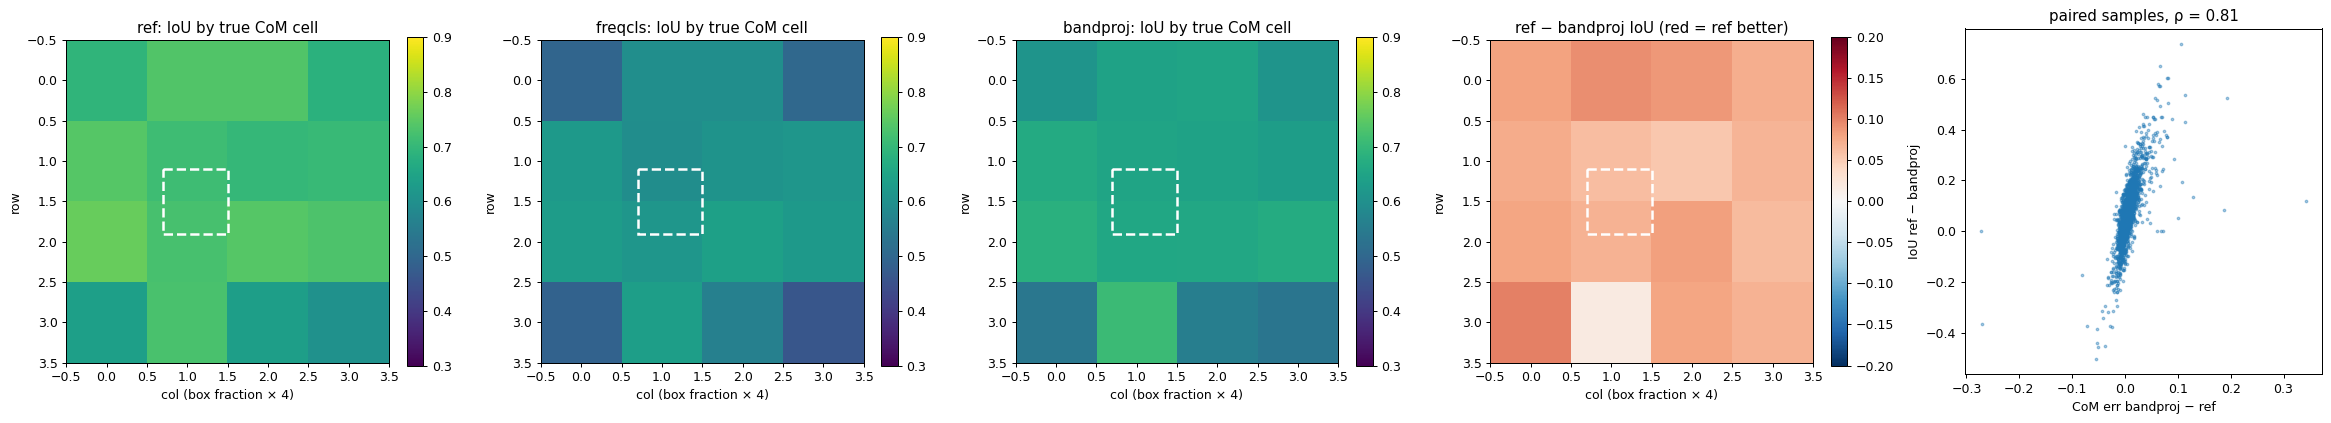

white dashed box = the held-out vase region (unseen-position split)
ID one-object: IoU gap 0.071, shape-IoU gap 0.058 -> location explains ~18% of the gap, shape/area ~82%
unseen position: IoU gap 0.063, shape-IoU gap 0.039 -> location explains ~38% of the gap, shape/area ~62%


In [8]:
fig, axs = plt.subplots(1, 5, figsize=(26, 4.8))
gb = lambda d, v: d.groupby([np.clip((d.com_r * 4).astype(int), 0, 3), np.clip((d.com_c * 4).astype(int), 0, 3)])[v].mean().unstack().reindex(index=range(4), columns=range(4))
for ax, r in zip(axs[:3], RUNS):
    im = ax.imshow(gb(d0[r], "iou"), vmin=.3, vmax=.9, cmap="viridis"); ax.set_title(f"{r}: IoU by true CoM cell"); plt.colorbar(im, ax=ax, fraction=.046)
g = gb(d0["ref"], "iou") - gb(d0["bandproj"], "iou")
im = axs[3].imshow(g, cmap="RdBu_r", vmin=-.2, vmax=.2); axs[3].set_title("ref − bandproj IoU (red = ref better)"); plt.colorbar(im, ax=axs[3], fraction=.046)
rr = REGION = D9.REGION
for ax in axs[:4]: ax.add_patch(plt.Rectangle((rr[2] * 4 - .5, rr[0] * 4 - .5), (rr[3] - rr[2]) * 4, (rr[1] - rr[0]) * 4, fill=False, ec="w", lw=2, ls="--"))
for ax in axs[:4]: ax.set(xlabel="col (box fraction × 4)", ylabel="row")
dg, dc = d0["ref"].iou.values - d0["bandproj"].iou.values, d0["bandproj"].com_err.values - d0["ref"].com_err.values
axs[4].scatter(dc, dg, s=4, alpha=.4); axs[4].set(xlabel="CoM err bandproj − ref", ylabel="IoU ref − bandproj", title=f"paired samples, ρ = {pd.Series(dc).corr(pd.Series(dg), method='spearman'):.2f}")
plt.tight_layout(); plt.show()
print("white dashed box = the held-out vase region (unseen-position split)")
# how much of the ID one-object gap would vanish if bandproj had ref's location? = gap in IoU minus gap in shape IoU
for grp, dd in [("ID one-object", d0), ("unseen position", {r: one(r)[one(r).category == "unseen-position"] for r in RUNS})]:
    gi, gs = dd["ref"].iou.mean() - dd["bandproj"].iou.mean(), dd["ref"].shape_iou.mean() - dd["bandproj"].shape_iou.mean()
    print(f"{grp}: IoU gap {gi:.3f}, shape-IoU gap {gs:.3f} -> location explains ~{(gi - gs) / gi:.0%} of the gap, shape/area ~{gs / gi:.0%}")

**B · reading.** The gap is **spread over everything**, not concentrated in one place. Every ID split loses .05–.10. The categories rank
multiple (.083) > control (.076) > id (.071) > unseen-angle (.065) ≈ unseen-position (.063) > unseen-speaker (.056) > rotated (.048) > unseen-object (.038) >
cylinder / laser / lid (≤ .025, where everyone is near the floor). The largest single splits are cardboard/cube-rotated (.175), the gastro
two-object splits (.14) and gastro cube-unseen-speaker-baseline (.138). Per object: cube (.085) and the two-object scenes (.083) lose most, candle
least (.058). Per box (ID): gastro .084, cardboard .079, plastic .057. On the box floor the gap is about uniform (it is smallest at the centre /
held-out region). Small masks lose more than large ones (Q1 .085 → Q4 .056).

**What kind of error:** mostly **shape / extent**, not location. Re-centering every prediction on the true CoM closes only ~18% of the ID
one-object gap (IoU gap .071 → shape-IoU gap .058). For unseen positions the share is ~38%. CoM errors are tiny in both models (.024 vs .018 of
the box ≈ 1.5 vs 1.2 px). The paired per-sample ρ = .81 between CoM-error difference and IoU difference mostly reflects that a ~1 px shift costs
a lot of IoU on a 36-px mask. bandproj **over-paints**: precision .69 vs .77, recall .875 vs .891, predicted / true area 1.25 vs 1.14.
Its masks are blurrier and fatter. That fits under-fitting: the ID BCE is almost the same (.034 vs .032), while the probability mass around the
0.08 threshold is more diffuse.

## load the ep200 (and ep100) checkpoints and the samples
300 **train** samples (with objects), 300 **ID eval** samples (one + two object) and 100 **unseen-position** samples, as nb116. `encode` is the
encoder written out (now with `band_proj`) so it can keep every intermediate; it is checked against the real forward.

In [9]:
def build(r, ep=200):
    sd = torch.load(ROOT / f"runs/{RUN_DIR[r]}/checkpoints/ep{ep}-ba{ep * 10}-rank0.pt", weights_only=False, map_location="cpu")["state"]["model"]
    nobj, K = sd["object_head.2.weight"].shape[0], sd["n_objects_head.2.weight"].shape[0] - 1
    info = dict(freq_range=(100.0, 1000.0), n_freqs=1170, n_laser_rows=10, n_laser_cols=10, n_channels=2, boxes=NAMES,
                cum_mean=sd["encoder.cum_mean"], cum_var=sd["encoder.cum_std"].pow(-2), objects=[str(i) for i in range(nobj + 1)], n_objects=list(range(K + 1)))
    m = Transformer2(info, **FLAGS[r]); m.load_state_dict(sd, strict=True)
    return m.eval().to(DEV)

ev = {"id": [], "unseen-position": []}
for f in sorted((ROOT / f"runs/{RUNS['ref']}/outputs_history/eval").glob("*/*/ep0200-ba*.pt")):
    c = CAT.get((f.parent.parent.name, f.parent.name)); c = "id" if c == "multiple" else c
    if c not in ev: continue
    info = torch.load(f, weights_only=False, map_location="cpu")["info"]
    ev[c] += [(info["experiment"][i], int(info["sample_id"][i]), int(info["position_id"][i]), int(info["speaker"][i])) for i in range(len(info["experiment"]))]
samples, idxs = D9.load_splits()
metas = list(samples.values())
tr = [(m["experiment"], int(m["sample_id"]) if m["sample_id"].isdigit() else -1, int(m["position_id"]), int(m["speaker"])) for m in (metas[i] for i in idxs["train"]) if m["n_objects"] > 0]
del samples, metas
pick = lambda L, n: [L[i] for i in np.random.choice(len(L), n, replace=False)]
SEL = [("train", s) for s in pick(tr, 300)] + [("id", s) for s in pick(ev["id"], 300)] + [("unseen-position", s) for s in pick(ev["unseen-position"], 100)]
X, BOXN, Y, NOBJ = [], [], [], []
for _, (exp, sid, pos, spk) in SEL:
    d = score.sample_dir(exp, sid, pos, spk); meta = D9.load_meta(d)
    s = D9.load_fft(d, meta, "tukey").abs(); X.append((s / s.std()).float().to(DEV)); BOXN.append(meta["box"]); NOBJ.append(meta["n_objects"])
    Y.append(score.truth(exp, sid, pos, spk, 64, 64))
X, Y, NOBJ = torch.stack(X), np.stack(Y), np.array(NOBJ)                         # X lives on the GPU (655 MB): keeps CPU RAM < 6 GB
GROUP = np.array([g for g, _ in SEL]); N = len(SEL)
NAMES = sorted(set(BOXN)); BOX = torch.tensor([NAMES.index(b) for b in BOXN]); print("boxes", NAMES)
G = {g: np.where(GROUP == g)[0] for g in ["train", "id", "unseen-position"]}
print("X", tuple(X.shape), {g: len(v) for g, v in G.items()})

2026_09_27_gastronorm_four_objs: 6155 samples


2026_10_05_green_plastic_four_objs: 5736 samples


2026_10_11_cardboard_four_objs: 7228 samples


split                                          samples    positions
-------------------------------------------  ---------  -----------
train                                            11219         3032
eval/gastro/vase                                   135           45
eval/gastro/candle                                 156           52
eval/gastro/cube                                   147           49
eval/gastro/cube-unseen-speaker-baseline           105           35
eval/gastro/cube-unseen-speaker-unseen              35           35
eval/gastro/soap-dispenser                         146           49
eval/gastro/cube-vase                               27            9
eval/gastro/two-cubes                               42           14
eval/gastro/cube-with-lid                           15            5
eval/gastro/cube-without-lid                        15            5
eval/gastro/cylinder-1000g                          27            9
eval/gastro/cylinder-500g                       

boxes ['cardboard', 'gastronorm', 'green-plastic']
X (700, 100, 1170, 2) {'train': 300, 'id': 300, 'unseen-position': 100}


In [10]:
def attn(blk, x):
    q, k, _ = blk.qkv(blk.n1(x)).view(*x.shape[:2], 3, blk.h, -1).permute(2, 0, 3, 1, 4)
    return (q @ k.transpose(-1, -2) / math.sqrt(q.shape[-1])).softmax(-1)

@torch.no_grad()
def encode(m, x, bx, keep=False):
    """the transformer2 encoder written out. keep=True also returns the band tokens after every layer and the last block's per-band summands"""
    e, fe, le = m.encoder, m.encoder.freq_enc, m.encoder.laser_enc
    B, L = x.shape[:2]
    xn = e.normalize(x, bx); xb = xn.reshape(B, L, 18, -1)
    laser = e.laser_emb + e.laser_pos(e.laser_fourier)
    lin = torch.einsum("blpi,pid->blpd", xb, fe.embed_w) + fe.embed_b if fe.band_proj else fe.embed(xb)
    t = (lin + fe.freq_band_emb(e.freq_band_logf[:, None])[None, None] + laser[None, :, None] + fe.box_emb(bx)[:, None, None]).flatten(0, 1)
    if fe.cls: t = torch.cat([fe.freq_cls.expand(len(t), 1, -1), t], 1)
    out, o = {}, 1 if fe.cls else 0
    if keep: out["h0"] = t[:, o:].view(B, L, 18, -1).cpu()
    FA = []
    for i, blk in enumerate(fe.freqs):
        a = attn(blk, t); FA.append(a[:, :, 0, 1:] if fe.cls else a.mean(2))
        if keep and fe.cls and i == len(fe.freqs) - 1:                                 # last block: cls output = cls_in + O(Σ_b α_b V n1(h_b) + α_c V n1(cls)) + MLP
            v = F.linear(blk.n1(t), blk.qkv.weight[256:], blk.qkv.bias[256:]).view(len(t), -1, blk.h, 32)   # (BL,19,H,32)
            s = (a[:, :, 0].permute(0, 2, 1)[..., None] * v)                            # (BL,19,H,32) α_t V x_t per head
            out["summand"] = torch.einsum("btd,od->bto", s.flatten(2), blk.o.weight).view(B, L, 19, -1).cpu()  # O(α_t V x_t): token t's contribution, (B,L,19,d)
        t = blk(t)
        if keep: out[f"h{i + 1}"] = t[:, o:].view(B, L, 18, -1).cpu()
    out["freq_attn"] = torch.stack(FA, 1).view(B, L, len(FA), fe.heads, -1).cpu()       # cls: what the cls reads (layers,H,18); ref: mean attention each band receives
    if fe.cls: raw = t[:, 0].view(B, L, -1)
    else:
        t = t.view(B, L, 18, -1)
        k = fe.pool_k(fe.pool_norm(t)).view(B, L, 18, fe.heads, -1)
        g = torch.einsum("blphe,he->blhp", k, fe.pool_q).div(math.sqrt(k.shape[-1])).softmax(-1).mean(2) * 18
        out["gate"] = g.cpu(); raw = fe.pool_o((t * g[..., None]).reshape(B, L, -1))
        if keep: out["summand"] = torch.einsum("obi,xlbi->xlbo", fe.pool_o.weight.view(128, 18, 128).permute(0, 1, 2), t * g[..., None]).cpu()  # g_b W_b h_b
    out["raw"], out["tok"] = raw.cpu(), (raw + laser).cpu()
    z = raw + laser
    for blk in le.lasers: z = blk(z)
    emb = le.to_emb(z); out["emb"] = emb.cpu()
    y = m.decoder(emb); out["mask"] = y[:, 0].sigmoid().cpu(); out["logit"] = y[:, 0].cpu()
    return out

def run(m, idx, keep=False, bs=25, xs=None):
    xs = X if xs is None else xs
    outs = [encode(m, xs[idx[i:i + bs]].to(DEV), BOX[idx[i:i + bs]].to(DEV), keep) for i in range(0, len(idx), bs)]
    return {k: torch.cat([o[k] for o in outs]) for k in outs[0]}
M = {r: build(r) for r in RUNS}
with torch.no_grad():
    for r, m in M.items():
        xx, bb = X[:4].to(DEV), BOX[:4].to(DEV); assert torch.allclose(m.decoder(m.encoder(xx, bb))[:, 0].sigmoid().cpu(), encode(m, xx, bb)["mask"], atol=1e-5), r
ALL = np.arange(N)
O = {r: run(m, ALL) for r, m in M.items()}
def ious(P, idx): return np.array([((P[i] > THR) & (Y[i] > .5)).sum() / max(((P[i] > THR) | (Y[i] > .5)).sum(), 1) for i in idx])
def bce(lg, idx): return F.binary_cross_entropy_with_logits(lg[idx], torch.as_tensor(Y[idx])).item()
fit = {}
for r in RUNS:
    m100 = build(r, 100); O100 = run(m100, ALL); del m100
    for ep, OO in [(100, O100), (200, O[r])]:
        fit[(r, ep)] = {**{f"IoU {g}": ious(OO["mask"].numpy(), ix).mean() for g, ix in G.items()}, **{f"BCE {g}": bce(OO["logit"], ix) for g, ix in G.items()}}
        if ep == 100: O100_attn = OO["freq_attn"]
    if FLAGS[r]["freq_cls"]:
        for ep, a in [(100, O100_attn), (200, O[r]["freq_attn"])]:
            fit[(r, ep)]["cls entropy"] = (-(a * a.clamp_min(1e-12).log()).sum(-1) / math.log(18)).mean().item()
fit = pd.DataFrame(fit).T; fit["train−id IoU"] = fit["IoU train"] - fit["IoU id"]
display(fit.round(3))

tokenize freqs [100, 1000] Hz of 1170 bins to 18 bands of 65 bins: [(100, 149), (150, 199), (200, 249), (250, 299), (300, 349), (350, 399), (400, 450), (450, 500), (500, 550), (550, 600), (600, 650), (650, 700), (701, 750), (751, 800), (801, 850), (851, 900), (901, 950), (951, 1000)]


tokenize freqs [100, 1000] Hz of 1170 bins to 18 bands of 65 bins: [(100, 149), (150, 199), (200, 249), (250, 299), (300, 349), (350, 399), (400, 450), (450, 500), (500, 550), (550, 600), (600, 650), (650, 700), (701, 750), (751, 800), (801, 850), (851, 900), (901, 950), (951, 1000)]


tokenize freqs [100, 1000] Hz of 1170 bins to 18 bands of 65 bins: [(100, 149), (150, 199), (200, 249), (250, 299), (300, 349), (350, 399), (400, 450), (450, 500), (500, 550), (550, 600), (600, 650), (650, 700), (701, 750), (751, 800), (801, 850), (851, 900), (901, 950), (951, 1000)]


tokenize freqs [100, 1000] Hz of 1170 bins to 18 bands of 65 bins: [(100, 149), (150, 199), (200, 249), (250, 299), (300, 349), (350, 399), (400, 450), (450, 500), (500, 550), (550, 600), (600, 650), (650, 700), (701, 750), (751, 800), (801, 850), (851, 900), (901, 950), (951, 1000)]


tokenize freqs [100, 1000] Hz of 1170 bins to 18 bands of 65 bins: [(100, 149), (150, 199), (200, 249), (250, 299), (300, 349), (350, 399), (400, 450), (450, 500), (500, 550), (550, 600), (600, 650), (650, 700), (701, 750), (751, 800), (801, 850), (851, 900), (901, 950), (951, 1000)]


tokenize freqs [100, 1000] Hz of 1170 bins to 18 bands of 65 bins: [(100, 149), (150, 199), (200, 249), (250, 299), (300, 349), (350, 399), (400, 450), (450, 500), (500, 550), (550, 600), (600, 650), (650, 700), (701, 750), (751, 800), (801, 850), (851, 900), (901, 950), (951, 1000)]


IoU train  IoU id  IoU unseen-position  BCE train  BCE id  BCE unseen-position  cls entropy  train−id IoU
ref      100      0.666   0.603                0.592      0.022   0.033                0.043          NaN         0.063
         200      0.819   0.685                0.641      0.008   0.032                0.046          NaN         0.134
freqcls  100      0.466   0.394                0.367      0.052   0.072                0.092        0.935         0.072
         200      0.670   0.553                0.542      0.019   0.043                0.049        0.936         0.117
bandproj 100      0.516   0.449                0.449      0.040   0.057                0.075        0.936         0.067
         200      0.720   0.612                0.588      0.014   0.034                0.043        0.937         0.108

The ep100 / ep200 fits on these samples match the logs. Note the **BCE** column: on ID eval bandproj (.034) is almost as good as ref (.032),
on unseen-position it is *better* (.043 vs .046), while its *thresholded* IoU is .07 lower. So part of the IoU gap is how the probability mass
is spread around the 0.08 threshold (B: bandproj over-paints, area ratio 1.25 vs 1.14). Below: IoU as a function of the threshold.

In [11]:
thrs = [.04, .08, .12, .16, .2, .3, .4, .5]
th = pd.DataFrame({r: {t: np.mean([((O[r]["mask"][i].numpy() > t) & (Y[i] > .5)).sum() / max(((O[r]["mask"][i].numpy() > t) | (Y[i] > .5)).sum(), 1) for i in G["id"]]) for t in thrs} for r in RUNS}).T
th["best thr"] = th[thrs].idxmax(1); th["best IoU"] = th[thrs].max(1)
soft = {r: (torch.minimum(O[r]["mask"][G["id"]], torch.as_tensor(Y[G["id"]])).flatten(1).sum(1) / torch.maximum(O[r]["mask"][G["id"]], torch.as_tensor(Y[G["id"]])).flatten(1).sum(1)).mean().item() for r in RUNS}
th["soft IoU"] = pd.Series(soft)
display(th.round(3)); print("gap ref − bandproj at .08:", round(th.loc["ref", .08] - th.loc["bandproj", .08], 3), " at each run's best threshold:", round(th.loc["ref", "best IoU"] - th.loc["bandproj", "best IoU"], 3))

/tmp/ipykernel_196652/3145180522.py:3: Pandas4Warning: Starting with pandas version 4.0 all arguments of max will be keyword-only.
  th["best thr"] = th[thrs].idxmax(1); th["best IoU"] = th[thrs].max(1)


,0.04,0.08,0.12,0.16,0.2,0.3,0.4,0.5,best thr,best IoU,soft IoU
ref,0.677,0.685,0.688,0.690,0.689,0.690,0.688,0.686,0.3,0.690,0.683
freqcls,0.543,0.553,0.556,0.560,0.561,0.562,0.558,0.551,0.3,0.562,0.539
bandproj,0.595,0.612,0.621,0.624,0.627,0.629,0.627,0.621,0.3,0.629,0.603


gap ref − bandproj at .08: 0.072  at each run's best threshold: 0.061


## C · inside the frequency encoder
### C1 · does the `[cls]` attention still go ~uniform?
Entropy over the 18 bands of what the `[cls]` reads (1 = uniform), per layer and head, and the weight it puts on itself. For ref: the gate's entropy.

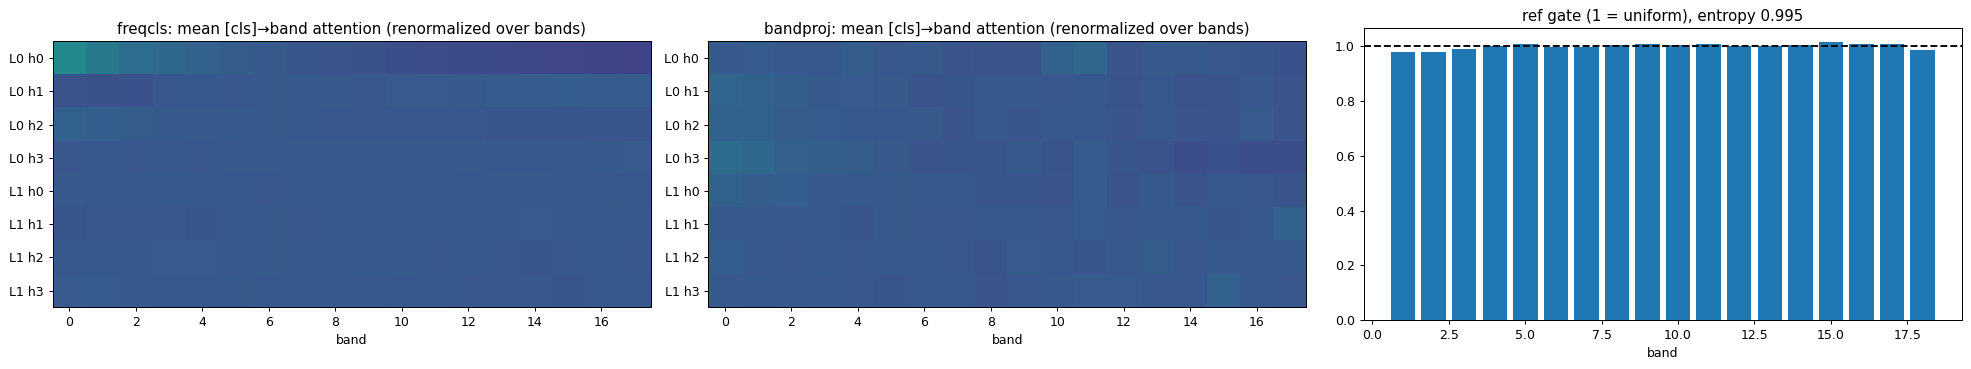

entropy  max_band_w  self_w
freqcls  L0 h0    0.973       0.114   0.020
         L0 h1    0.950       0.128   0.031
         L0 h2    0.996       0.075   0.043
         L0 h3    0.977       0.102   0.070
         L1 h0    0.978       0.099   0.093
         L1 h1    0.984       0.093   0.075
         L1 h2    0.950       0.128   0.058
         L1 h3    0.983       0.095   0.086
bandproj L0 h0    0.974       0.111   0.059
         L0 h1    0.991       0.084   0.048
         L0 h2    0.987       0.090   0.057
         L0 h3    0.981       0.098   0.025
         L1 h0    0.985       0.097   0.075
         L1 h1    0.985       0.097   0.049
         L1 h2    0.988       0.092   0.214
         L1 h3    0.986       0.094   0.056

In [12]:
ID = G["id"]
fig, axs = plt.subplots(1, 3, figsize=(22, 4.2))
rows = {}
for j, r in enumerate(["freqcls", "bandproj"]):
    a = O[r]["freq_attn"][ID]                                                           # (S,L,layers,H,18): weights on the bands (self weight = 1 − sum)
    b = a / a.sum(-1, keepdim=True); ent = -(b * b.clamp_min(1e-12).log()).sum(-1) / math.log(18)
    for l in range(a.shape[2]):
        for h in range(a.shape[3]): rows[(r, f"L{l} h{h}")] = dict(entropy=ent[:, :, l, h].mean().item(), max_band_w=b[:, :, l, h].max(-1).values.mean().item(), self_w=(1 - a[:, :, l, h].sum(-1)).mean().item())
    axs[j].imshow(b.mean((0, 1)).reshape(-1, 18), cmap="viridis", vmin=0, vmax=.2); axs[j].set_title(f"{r}: mean [cls]→band attention (renormalized over bands)")
    axs[j].set_yticks(range(8), [f"L{x} h{y}" for x in range(2) for y in range(4)]); axs[j].set_xlabel("band")
g = O["ref"]["gate"][ID] / 18; ge = (-(g * g.clamp_min(1e-12).log()).sum(-1) / math.log(18)).mean().item()
axs[2].bar(range(1, 19), (g * 18).mean((0, 1))); axs[2].axhline(1, color="k", ls="--"); axs[2].set(title=f"ref gate (1 = uniform), entropy {ge:.3f}", xlabel="band")
plt.tight_layout(); plt.show()
display(pd.DataFrame(rows).T.round(3))

### C2 · probes on the per-laser freq token and on the band tokens
Rows are (sample, laser) of the 300 ID samples, each laser's mean over samples removed; ridge (λ picked on a held-out slice), fit on 80% of
samples, R² on the other 20%. For each run (band tokens `h^l` = after layer l, `h^0` = embedded input):
* **folding test (input)**: R² of the token from the full patch (18×130) vs from the band-averaged patch (130). Ratio ≈ 1 = folded.
* **folding test (hidden)**: R² of the token from the concatenated band tokens `concat_b h_b^l` (2304) vs their band-mean `mean_b h_b^l` (128).
  This is the key test: if the token only sees the band-mean of the **nonlinear** features, the mean explains as much as the concat.
* **band energy** (18 targets, linear in the input) and **nonlinear per-band features** (per band: std of its 130 z-scores, max, and the
  energy-weighted bin centroid, 54 targets), decoded from the input (linearly), from `concat h^1`, `concat h^2` and from the token.
* **band recoverability**: each band's own top-4 PCs (72 targets) decoded from `mean_b h_b^l`, per layer. High = the bands live in separate
  subspaces so a sum/average still keeps them apart; this is what `W_x^b` buys at layer 0. Does it survive the blocks?
* **Σ summands**: share of the token's sample-dependent variance that is the sum of the per-band summands of the readout
  (cls: `O·α_b V h_b` of the last block; ref: `g_b W_b h_b`), and the mean cosine between those summands of one laser.

In [13]:
def center(T): T = T.float(); return (T - T.mean(0, keepdim=True)).flatten(0, 1)        # (S,L,·) -> (S·L,·), per-laser mean removed
def ridge(Xtr, Ytr, Xte, Yte, lam):
    Xtr, Ytr, Xte, Yte = [t.to(DEV).double() for t in (Xtr, Ytr, Xte, Yte)]
    mu, sd = Xtr.mean(0), Xtr.std(0) + 1e-8; A, Bm = (Xtr - mu) / sd, (Xte - mu) / sd
    w = torch.linalg.solve(A.T @ A + lam * len(A) * torch.eye(A.shape[1], dtype=torch.float64, device=DEV), A.T @ (Ytr - Ytr.mean(0)))
    res = Yte - Ytr.mean(0) - Bm @ w
    return (1 - res.pow(2).sum(0) / (Yte - Yte.mean(0)).pow(2).sum(0)).float().cpu()
def probe(Xf, Yf, S, lams=(1e-3, 1e-2, 1e-1)):
    """rows (sample, laser): λ by a 60/20 split of the first 80% of samples, then refit on 80%, R² per target on the last 20%"""
    n, v = int(S * .8) * 100, int(S * .6) * 100
    lam = max(lams, key=lambda l: ridge(Xf[:v], Yf[:v], Xf[v:n], Yf[v:n], l).mean().item())
    return ridge(Xf[:n], Yf[:n], Xf[n:], Yf[n:], lam)
IDP = ID[:200]; S = len(IDP)                                                           # 200 ID samples = 20,000 (sample, laser) rows: keeps CPU RAM < 6 GB
xb = M["ref"].encoder.normalize(X[IDP].to(DEV), BOX[IDP].to(DEV)).reshape(S, 100, 18, 65, 2).cpu()   # the input, the same for every run
energy = center(xb.mean((-1, -2)))
pw = xb.pow(2).sum(-1)                                                                  # (S,L,18,65) energy per bin
nonlin = center(torch.cat([xb.flatten(-2).std(-1), xb.flatten(-2).amax(-1), (pw * torch.arange(65.)).sum(-1) / pw.sum(-1)], -1))  # (S·L,54)
full, folded = center(xb.flatten(2)), center(xb.mean(2).flatten(2))
NL_IN = probe(full, nonlin, S)                                                         # how linear the nonlinear targets are in the input
print(f"input -> band energy R² {probe(full, energy, S).mean():.3f};  input -> nonlinear per-band targets R² {NL_IN.mean():.3f} "
      f"(std {NL_IN[:18].mean():.3f}, max {NL_IN[18:36].mean():.3f}, centroid {NL_IN[36:].mean():.3f})")

def top_pcs(T, k=4):
    """(S·L,18,d) -> (S·L,18·k) each band's own top-k principal-component scores"""
    out = []
    for b in range(18):
        Z = T[:, b] - T[:, b].mean(0); U, s, V = torch.linalg.svd(Z.to(DEV).double(), full_matrices=False); out.append((Z.to(DEV).double() @ V[:k].T).float().cpu())
    return torch.cat(out, 1)

PR, BANDR2 = {}, {}
for r in RUNS:
    K = run(M[r], IDP, keep=True)
    tok = center(K["raw"]); res = {}
    res["token R² from input (full)"] = probe(full, tok, S).mean().item()
    res["token R² from input (band-avg)"] = probe(folded, tok, S).mean().item()
    res["input folded/full"] = res["token R² from input (band-avg)"] / res["token R² from input (full)"]
    for l in range(3):
        H = K[f"h{l}"]; Hc = center(H.flatten(2)); Hm = center(H.mean(2))
        res[f"token R² from concat h{l}"] = probe(Hc, tok, S).mean().item(); res[f"token R² from mean h{l}"] = probe(Hm, tok, S).mean().item()
        res[f"h{l} folded/full"] = res[f"token R² from mean h{l}"] / res[f"token R² from concat h{l}"]
        res[f"band recoverability from mean h{l}"] = probe(Hm, top_pcs(Hc.view(-1, 18, 128)), S).mean().item()
        if l > 0: res[f"nonlinear R² from concat h{l}"] = probe(Hc, nonlin, S).mean().item()
        del Hc, Hm, H, K[f"h{l}"]
    e_r2, n_r2 = probe(tok, energy, S), probe(tok, nonlin, S)
    res["band energy R² from token"], res["nonlinear R² from token"] = e_r2.mean().item(), n_r2.mean().item()
    U = torch.linalg.svd(tok.to(DEV).double(), full_matrices=False)[2]                  # token PCs, by variance
    for k in (4, 8, 16, 32): res[f"band energy R² from top-{k} token PCs"] = probe((tok.to(DEV).double() @ U[:k].T).float().cpu(), energy, S).mean().item()
    res["nonlinear retained (token / concat h2)"] = res["nonlinear R² from token"] / res["nonlinear R² from concat h2"]
    sm = K["summand"][:, :, -18:]                                                        # band summands only (cls: drop the cls→cls term)
    ssum = center(sm.sum(2)); res["token R² from Σ band summands"] = probe(ssum, tok, S).mean().item()
    res["var(Σ summands)/var(token)"] = (ssum.var(0).sum() / tok.var(0).sum()).item()
    Tn = F.normalize((sm - sm.mean(0, keepdim=True)).float(), dim=-1); cos = torch.einsum("slbd,slcd->bc", Tn, Tn) / (Tn.shape[0] * Tn.shape[1])
    res["cos between band summands"] = cos[~torch.eye(18, dtype=bool)].mean().item()
    T = K["tok"].double(); dev = T - T.mean(0, keepdim=True); sv = torch.linalg.svdvals(dev.flatten(0, 1)) ** 2
    res["sample-dep share of token"] = (dev.pow(2).sum() / (T - T.mean((0, 1), keepdim=True)).pow(2).sum()).item()
    res["eff rank (sample-dep)"] = (sv.sum() ** 2 / (sv ** 2).sum()).item()
    rw = K["raw"].double(); dv = rw - rw.mean(0, keepdim=True); spec = dv - dv.mean(1, keepdim=True)
    res["laser-specific share"] = (spec.pow(2).sum() / dv.pow(2).sum()).item()
    PR[r] = res; BANDR2[r] = dict(energy=e_r2, nonlin=n_r2)
    del K, tok, sm, Tn
    torch.cuda.empty_cache()
del full, folded, xb, pw, nonlin
PR = pd.DataFrame(PR); display(PR.round(3))

input -> band energy R² 1.000;  input -> nonlinear per-band targets R² 0.305 (std 0.238, max 0.555, centroid 0.123)


,ref,freqcls,bandproj
token R² from input (full),0.837,0.392,0.442
token R² from input (band-avg),0.092,0.385,0.085
input folded/full,0.110,0.983,0.192
token R² from concat h0,0.939,0.796,0.763
token R² from mean h0,0.180,0.780,0.758
h0 folded/full,0.192,0.980,0.993
band recoverability from mean h0,0.624,0.631,0.952
token R² from concat h1,0.974,0.900,0.899
token R² from mean h1,0.193,0.872,0.791
h1 folded/full,0.199,0.970,0.880


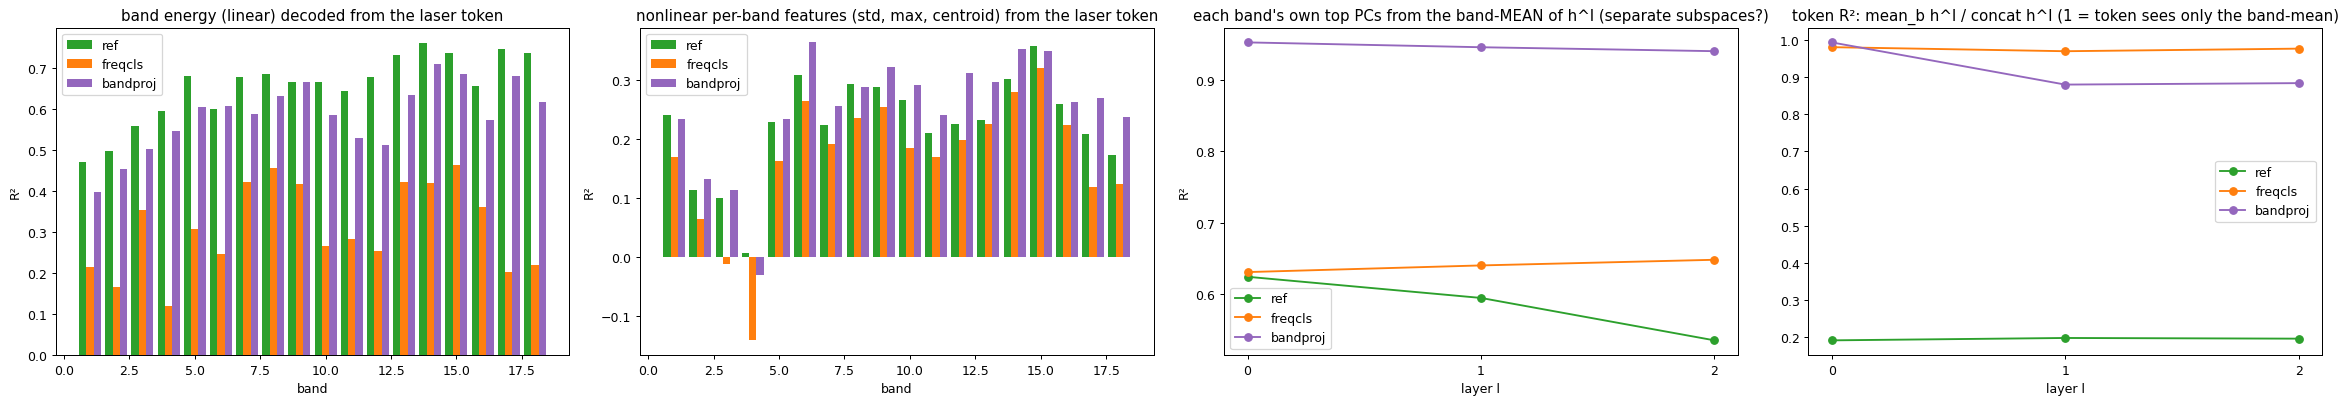

In [14]:
fig, axs = plt.subplots(1, 4, figsize=(26, 4.6))
w = .28
for i, r in enumerate(RUNS):
    axs[0].bar(np.arange(1, 19) + (i - 1) * w, BANDR2[r]["energy"].numpy(), w, color=COL[r], label=r)
    axs[1].bar(np.arange(1, 19) + (i - 1) * w, BANDR2[r]["nonlin"].view(3, 18).mean(0).numpy(), w, color=COL[r], label=r)
axs[0].set(title="band energy (linear) decoded from the laser token", xlabel="band", ylabel="R²"); axs[0].legend()
axs[1].set(title="nonlinear per-band features (std, max, centroid) from the laser token", xlabel="band", ylabel="R²"); axs[1].legend()
for i, r in enumerate(RUNS):
    axs[2].plot(range(3), [PR.loc[f"band recoverability from mean h{l}", r] for l in range(3)], "o-", color=COL[r], label=r)
    axs[3].plot(range(3), [PR.loc[f"h{l} folded/full", r] for l in range(3)], "o-", color=COL[r], label=r)
axs[2].set(title="each band's own top PCs from the band-MEAN of h^l (separate subspaces?)", xlabel="layer l", ylabel="R²", xticks=range(3)); axs[2].legend()
axs[3].set(title="token R²: mean_b h^l / concat h^l (1 = token sees only the band-mean)", xlabel="layer l", xticks=range(3)); axs[3].legend()
plt.tight_layout(); plt.show()

**C · reading.**
* **The `[cls]` attention is still uniform**: entropy .97–.99 in every layer and head (freqcls .95–.99), top band weight ~.09 (uniform .056).
  It does not sharpen (ep100 .936 → ep200 .937 averaged incl. self weight). So the readout is ≈ `O·V·mean_b h_b` plus an MLP.
* **`band_proj` does fix the linear folding**: token-from-band-averaged-input / token-from-full-input = .19 (ref .11, freqcls .98). Band energy
  decodes from the token at R² .58 (ref .65, freqcls .31).
* **The key hypothesis is not supported**: band identity of the *nonlinear* features is **not** lost. With `W_x^b` the 18 bands sit in separate
  subspaces, and they **stay** separate through both blocks: each band's top PCs can be recovered from the plain band-*mean* `mean_b h_b^l` at
  R² .95 / .95 / .94 for l = 0 / 1 / 2 (ref .62 → .54, freqcls .63–.65). So a shared V over a uniform average is close to lossless here.
  Nonlinear per-band features (std / max / centroid) decode from the bandproj token at R² .25, **at least as well as ref** (.23; freqcls .17), and
  bandproj keeps a larger fraction of what its band tokens hold (.43 vs .37). (The hidden folding ratio for bandproj, mean/concat ≈ .88–.99, is
  high *because* the mean is lossless, not because information is dropped.)
* **What does differ is the geometry of the token, not its information.** The per-band summands that add up to the token are correlated in
  bandproj (mean cosine .43, freqcls .40) and orthogonal in ref (−.01). So the token's sample variation is dominated by a common mode: sample-dependent
  share .31 (ref .84; lower even than freqcls .43), effective rank 11 (ref 34). The attention sum is only 46% of the token variance; the rest is the
  MLP on the cls. The ref token is an exact linear function of `concat_b h_b^2` (R² .985) with 18 orthogonal W_b.
* **After the laser stage the embedding holds about as much**: CoM probe R² .79 vs .81 (probe error on unseen positions is even *lower*, .080 vs
  .086), per-laser energy map R² .84 vs .80, per-band map .76 vs .73.

So the freq token of bandproj is **linearly about as informative** as ref's. The deficit is that the model fits slower and less sharply, which
points to the readout's form (a small-variance, low-rank, common-mode-dominated cls) and to optimization rather than to lost information.

### C3 · after the laser stage: what does the 1024-d embedding still hold?
Ridge fit on the 300 train samples' embeddings, tested on ID eval (and unseen-position for the CoM): the object's **CoM** (one-object samples),
the **per-laser energy map** (100 targets: where the spectrum changed), and the **per-band energy map** (18 targets, averaged over lasers:
which bands changed). The embedding is what the decoder sees, so these say what reaches it.

In [15]:
com = np.stack([np.argwhere(y > .5).mean(0) / 64 if (y > .5).any() else [np.nan, np.nan] for y in Y])
onem = (NOBJ == 1) & ~np.isnan(com[:, 0])
with torch.no_grad():
    zn = M["ref"].encoder.normalize(X.to(DEV), BOX.to(DEV)).reshape(N, 100, 18, -1).mean(-1).cpu()   # (N,100,18) energy per laser and band
lmap, bmap = zn.mean(-1), zn.mean(1)
def probe_s(feat, target, tr_idx, te_idx, lams=(1e-3, 1e-2, 1e-1, 1)):
    f, t = torch.as_tensor(feat).float(), torch.as_tensor(target).float()
    n = int(len(tr_idx) * .8); a, b = tr_idx[:n], tr_idx[n:]
    lam = max(lams, key=lambda l: ridge(f[a], t[a], f[b], t[b], l).mean().item())
    mu, sd = f[tr_idx].mean(0), f[tr_idx].std(0) + 1e-8; A = (f[tr_idx] - mu) / sd
    w = torch.linalg.solve((A.T @ A).double() + lam * len(A) * torch.eye(A.shape[1], dtype=torch.float64), (A.T @ (t[tr_idx] - t[tr_idx].mean(0))).double()).float()
    return ridge(f[tr_idx], t[tr_idx], f[te_idx], t[te_idx], lam).mean().item(), (t[tr_idx].mean(0) + ((f[te_idx] - mu) / sd) @ w).numpy()
trn, idn, posn = [np.where((GROUP == g) & onem)[0] for g in ["train", "id", "unseen-position"]]
EMB = {}
for r in RUNS:
    e = O[r]["emb"]
    r2c, pc = probe_s(e, com, trn, idn); _, pp = probe_s(e, com, trn, posn)
    EMB[r] = dict(CoM_R2_ID=r2c, CoM_probe_err_ID=np.linalg.norm(pc - com[idn], axis=1).mean(), CoM_probe_err_unseen_pos=np.linalg.norm(pp - com[posn], axis=1).mean(),
                  laser_map_R2_ID=probe_s(e, lmap, G["train"], G["id"])[0], band_map_R2_ID=probe_s(e, bmap, G["train"], G["id"])[0])
display(pd.DataFrame(EMB).T.round(3))

,CoM_R2_ID,CoM_probe_err_ID,CoM_probe_err_unseen_pos,laser_map_R2_ID,band_map_R2_ID
ref,0.808,0.100,0.086,0.799,0.726
freqcls,0.670,0.135,0.126,0.870,0.708
bandproj,0.786,0.109,0.080,0.837,0.760


## D · band occlusion: which bands does each model use?
For each band, all 100 lasers' 65 bins × 2 channels of that band are set to the train mean (= 0 after the per-box standardization), on the
300 ID samples. Δ = occluded − clean: IoU@.08 drop and mask-BCE rise. Then a cumulative version: remove bands from the least to the most
important (per run) and watch IoU, to see how many bands each model actually needs.

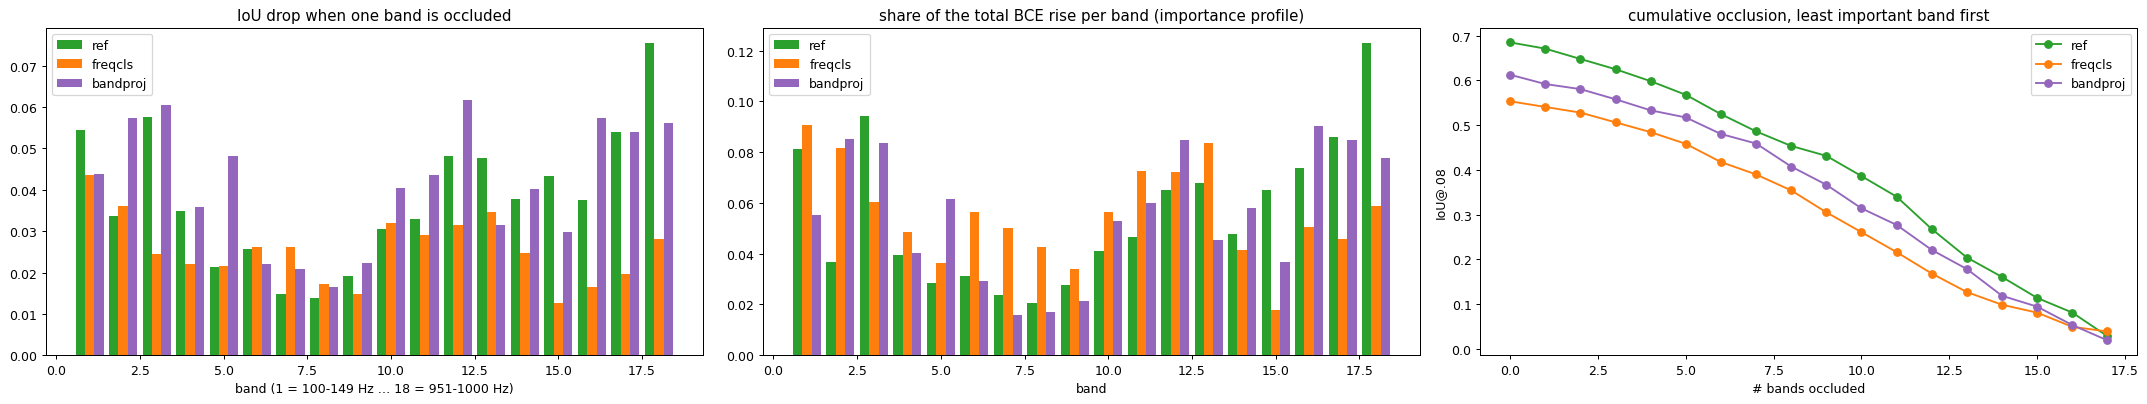

,clean_IoU,sum_dIoU,sum_dBCE,bands_for_80pct_dBCE,importance_entropy,IoU_keep_top6,IoU_keep_top3,spearman_vs_ref
ref,0.685,0.683,0.139,12.0,0.959,0.268,0.114,1.00
freqcls,0.553,0.461,0.097,13.0,0.980,0.168,0.081,0.41
bandproj,0.612,0.742,0.142,12.0,0.963,0.221,0.094,0.62


In [16]:
def occlude(m, bands, idx, bs=50):
    xs, cm, bi = X[idx].clone(), m.encoder.cum_mean, BOX[idx].to(DEV)
    for b in bands: xs[:, :, b * 65:(b + 1) * 65] = cm[bi, :, b * 65:(b + 1) * 65]
    outs = [encode(m, xs[i:i + bs].to(DEV), BOX[idx[i:i + bs]].to(DEV)) for i in range(0, len(idx), bs)]
    P, lg = torch.cat([o["mask"] for o in outs]).numpy(), torch.cat([o["logit"] for o in outs])
    yy = torch.as_tensor(Y[idx])
    return np.mean([((P[i] > THR) & (Y[j] > .5)).sum() / max(((P[i] > THR) | (Y[j] > .5)).sum(), 1) for i, j in enumerate(idx)]), F.binary_cross_entropy_with_logits(lg, yy).item()
OCC, CUM = {}, {}
for r in RUNS:
    i0, b0 = occlude(M[r], [], ID)
    d = np.array([occlude(M[r], [b], ID) for b in range(18)])
    OCC[r] = dict(dIoU=i0 - d[:, 0], dBCE=d[:, 1] - b0, iou0=i0)
    order = np.argsort(OCC[r]["dBCE"])                                                  # least important first
    CUM[r] = [i0] + [occlude(M[r], list(order[:k]), ID)[0] for k in range(1, 18)]
fig, axs = plt.subplots(1, 3, figsize=(24, 4.6)); w = .28
for i, r in enumerate(RUNS):
    axs[0].bar(np.arange(1, 19) + (i - 1) * w, OCC[r]["dIoU"], w, color=COL[r], label=r)
    axs[1].bar(np.arange(1, 19) + (i - 1) * w, OCC[r]["dBCE"] / OCC[r]["dBCE"].sum(), w, color=COL[r], label=r)
    axs[2].plot(range(18), CUM[r], "o-", color=COL[r], label=r)
axs[0].set(title="IoU drop when one band is occluded", xlabel="band (1 = 100-149 Hz … 18 = 951-1000 Hz)"); axs[0].legend()
axs[1].set(title="share of the total BCE rise per band (importance profile)", xlabel="band"); axs[1].legend()
axs[2].set(title="cumulative occlusion, least important band first", xlabel="# bands occluded", ylabel="IoU@.08"); axs[2].legend()
plt.tight_layout(); plt.show()
def n80(v): v = np.sort(np.clip(v, 0, None))[::-1]; return int(np.searchsorted(np.cumsum(v) / v.sum(), .8) + 1)
def ent(v): p = np.clip(v, 1e-12, None) / np.clip(v, 1e-12, None).sum(); return float(-(p * np.log(p)).sum() / np.log(len(p)))
display(pd.DataFrame({r: dict(clean_IoU=OCC[r]["iou0"], sum_dIoU=OCC[r]["dIoU"].sum(), sum_dBCE=OCC[r]["dBCE"].sum(), bands_for_80pct_dBCE=n80(OCC[r]["dBCE"]),
                               importance_entropy=ent(OCC[r]["dBCE"]), IoU_keep_top6=CUM[r][12], IoU_keep_top3=CUM[r][15],
                               spearman_vs_ref=pd.Series(OCC[r]["dBCE"]).corr(pd.Series(OCC["ref"]["dBCE"]), method="spearman")) for r in RUNS}).T.round(3))

**D · reading.** bandproj does **not** use fewer bands. 12 bands carry 80% of the BCE rise for both bandproj and ref (freqcls 13). The importance
entropy is .963 vs .959. Summed single-band IoU drop is .74 vs .68 for ref (freqcls .46: it uses the spectrum least). The profile is ref-like
(Spearman .62 with ref, freqcls .41): low bands 1–3 and the 600–1000 Hz bands matter, 350–500 Hz matters least. bandproj leans more on bands 2–5, 11–13 and 16
and less on 18 (ref's single most important band). Under cumulative occlusion it stays ~.06 below ref until both collapse. That is a uniform offset,
not a missing band.

## F · deciding between three candidate fixes
* **(A)** per-band weights in **every** layer (untied per band all the way through),
* **(B)** a **bigger** model (more freq layers / heads / head dim),
* **(C)** which projection to untie per band: **Q/K** (routing), **V** (content) or **O** (destination).

Models: ref, freqcls and bandproj at ep200, plus **matched-epoch** ep100 checkpoints of freqcls, bandproj and `freqcls8` (8 freq blocks; it only has
ep100). F1 uniform-attention ablation · F2 attention entropy / patterns · F3 where band identity is lost, layer by layer · F4 readout vs encoder
bottleneck (oracle untied readout on frozen band tokens) · F5 size: fit vs generalization, depth at matched epochs.

In [17]:
# 200 OOD eval samples (rotated / cylinder / unseen-object / unseen-speaker / unseen-laser / lid), on the GPU like X
oo = []
for f in sorted((ROOT / f"runs/{RUNS['ref']}/outputs_history/eval").glob("*/*/ep0200-ba*.pt")):
    if CAT.get((f.parent.parent.name, f.parent.name)) not in OOD_CATS: continue
    info = torch.load(f, weights_only=False, map_location="cpu")["info"]
    oo += [(info["experiment"][i], int(info["sample_id"][i]), int(info["position_id"][i]), int(info["speaker"][i])) for i in range(len(info["experiment"]))]
XO, BO, YO = [], [], []
for exp, sid, pos, spk in pick(oo, 200):
    d = score.sample_dir(exp, sid, pos, spk); meta = D9.load_meta(d)
    s = D9.load_fft(d, meta, "tukey").abs(); XO.append((s / s.std()).float().to(DEV)); BO.append(NAMES.index(meta["box"])); YO.append(score.truth(exp, sid, pos, spk, 64, 64))
XO, BO, YO = torch.stack(XO), torch.tensor(BO), np.stack(YO)
keep_o = YO.reshape(len(YO), -1).max(1) > .5; XO, BO, YO = XO[torch.as_tensor(keep_o).to(DEV)], BO[keep_o], YO[keep_o]   # empty-target samples are not scored
MF = {"ref": M["ref"], "freqcls": M["freqcls"], "bandproj": M["bandproj"], "freqcls@100": build("freqcls", 100), "bandproj@100": build("bandproj", 100), "freqcls8@100": build("freqcls8", 100)}
COL.update({"freqcls@100": "navajowhite", "bandproj@100": "plum", "freqcls8@100": "tab:brown"})
print("OOD samples", len(YO), "| models", {k: f"{len(m.encoder.freq_enc.freqs)} freq layers" for k, m in MF.items()})

tokenize freqs [100, 1000] Hz of 1170 bins to 18 bands of 65 bins: [(100, 149), (150, 199), (200, 249), (250, 299), (300, 349), (350, 399), (400, 450), (450, 500), (500, 550), (550, 600), (600, 650), (650, 700), (701, 750), (751, 800), (801, 850), (851, 900), (901, 950), (951, 1000)]
tokenize freqs [100, 1000] Hz of 1170 bins to 18 bands of 65 bins: [(100, 149), (150, 199), (200, 249), (250, 299), (300, 349), (350, 399), (400, 450), (450, 500), (500, 550), (550, 600), (600, 650), (650, 700), (701, 750), (751, 800), (801, 850), (851, 900), (901, 950), (951, 1000)]


tokenize freqs [100, 1000] Hz of 1170 bins to 18 bands of 65 bins: [(100, 149), (150, 199), (200, 249), (250, 299), (300, 349), (350, 399), (400, 450), (450, 500), (500, 550), (550, 600), (600, 650), (650, 700), (701, 750), (751, 800), (801, 850), (851, 900), (901, 950), (951, 1000)]
OOD samples 198 | models {'ref': '2 freq layers', 'freqcls': '2 freq layers', 'bandproj': '2 freq layers', 'freqcls@100': '2 freq layers', 'bandproj@100': '2 freq layers', 'freqcls8@100': '8 freq layers'}


In [18]:
@torch.no_grad()
def fwd(m, x, bx, uni_band=False, uni_read=False, keep=None, stats=None):
    """the encoder with the attention written out. uni_band: band-token query rows attend uniformly (1/T) in every freq layer; uni_read: the [cls]
    row attends uniformly in every layer (ref: its gate set to 1). keep = laser index list: also return the band tokens (and cls state) after every
    layer for those lasers. stats = dict to accumulate attention sums into"""
    e, fe, le = m.encoder, m.encoder.freq_enc, m.encoder.laser_enc
    B, L = x.shape[:2]
    xb = e.normalize(x, bx).reshape(B, L, 18, -1)
    laser = e.laser_emb + e.laser_pos(e.laser_fourier)
    lin = torch.einsum("blpi,pid->blpd", xb, fe.embed_w) + fe.embed_b if fe.band_proj else fe.embed(xb)
    t = (lin + fe.freq_band_emb(e.freq_band_logf[:, None])[None, None] + laser[None, :, None] + fe.box_emb(bx)[:, None, None]).flatten(0, 1)
    c = int(bool(fe.cls))
    if c: t = torch.cat([fe.freq_cls.expand(len(t), 1, -1), t], 1)
    T = t.shape[1]
    rows = torch.zeros(T, dtype=torch.bool, device=t.device); rows[c:] = uni_band
    if c: rows[0] = uni_read
    out = dict(H=[], C=[])
    snap = lambda t: (out["H"].append(t[:, c:].view(B, L, 18, -1)[:, keep].cpu()), out["C"].append(t[:, 0].view(B, L, -1)[:, keep].cpu() if c else None))
    if keep is not None: snap(t)
    for li, blk in enumerate(fe.freqs):
        N, _, D = t.shape
        q, k, v = blk.qkv(blk.n1(t)).view(N, T, 3, blk.h, -1).permute(2, 0, 3, 1, 4)
        a = (q @ k.transpose(-1, -2) / math.sqrt(q.shape[-1])).softmax(-1)              # (N,H,T,T)
        a = torch.where(rows[None, None, :, None], torch.full_like(a, 1 / T), a)
        if stats is not None:
            s = stats.setdefault(li, dict(n=0, sum=0, sq=0, ent=0, mx=0))
            s["n"] += N; s["sum"] = s["sum"] + a.sum(0); s["sq"] = s["sq"] + (a * a).sum(0)
            s["ent"] = s["ent"] + (-(a * a.clamp_min(1e-12).log()).sum(-1) / math.log(T)).sum(0); s["mx"] = s["mx"] + a.amax(-1).sum(0)   # (H,T) per query row
        t = t + blk.o((a @ v).transpose(1, 2).reshape(N, T, D)); t = t + blk.mlp(blk.n2(t))
        if keep is not None: snap(t)
    if c: raw = t[:, 0].view(B, L, -1)
    else:
        t = t.view(B, L, 18, -1)
        k = fe.pool_k(fe.pool_norm(t)).view(B, L, 18, fe.heads, -1)
        g = torch.ones(B, L, 18, device=t.device) if uni_read else torch.einsum("blphe,he->blhp", k, fe.pool_q).div(math.sqrt(k.shape[-1])).softmax(-1).mean(2) * 18
        raw = fe.pool_o((t * g[..., None]).reshape(B, L, -1))
    z = raw + laser
    for blk in le.lasers: z = blk(z)
    emb = le.to_emb(z); y = m.decoder(emb)
    out.update(raw=raw.cpu(), mask=y[:, 0].sigmoid().cpu(), logit=y[:, 0].cpu()); return out

def frun(m, xs, bs_, idx, bs=25, **kw):
    outs = [fwd(m, xs[idx[i:i + bs]], bs_[idx[i:i + bs]].to(DEV), **kw) for i in range(0, len(idx), bs)]
    return {k: torch.cat([o[k] for o in outs]) if isinstance(outs[0][k], torch.Tensor) else outs[0][k] for k in ("raw", "mask", "logit")} | \
           {k: [torch.cat([o[k][l] for o in outs]) if outs[0][k][l] is not None else None for l in range(len(outs[0][k]))] for k in ("H", "C")}
for r in RUNS:                                                                         # == the real forward (SDPA kernels differ in the last bits)
    dmax = (frun(MF[r], X, BOX, ID[:8])["mask"] - O[r]["mask"][ID[:8]]).abs().max().item(); print(f"{r}: max |Δmask| vs real forward {dmax:.1e}"); assert dmax < 1e-3, r

ref: max |Δmask| vs real forward 2.8e-05
freqcls: max |Δmask| vs real forward 1.0e-05
bandproj: max |Δmask| vs real forward 2.5e-05


### F1 · uniform-attention ablation at eval time
Replace softmax attention by uniform 1/T: **(a)** in every band-token query row of every freq layer (band↔band routing), **(b)** in the `[cls]`
row only (the readout; ref: the gate set to 1), and both. IoU@.08 drop on 300 ID, 100 unseen-position and the OOD samples.
~0 drop = the learned routing (Q/K) does nothing → untying Q/K per band is pointless.

,clean ID,clean unseen-pos,clean OOD
bandproj,0.612,0.588,0.343
bandproj@100,0.449,0.449,0.280
freqcls,0.553,0.542,0.315
freqcls8@100,0.460,0.431,0.266
freqcls@100,0.394,0.367,0.245
ref,0.685,0.641,0.381


uniform band↔band                   uniform readout                     both                  
                            ID unseen-pos    OOD              ID unseen-pos    OOD     ID unseen-pos    OOD
bandproj                -0.000     -0.001 -0.001           0.105      0.129  0.046  0.104      0.129  0.046
bandproj@100            -0.001     -0.004  0.001           0.036      0.068  0.025  0.035      0.065  0.026
freqcls                  0.001      0.008  0.001           0.153      0.220  0.095  0.154      0.221  0.096
freqcls8@100             0.004      0.004  0.002           0.083      0.102  0.060  0.092      0.109  0.064
freqcls@100              0.003      0.005 -0.001           0.117      0.145  0.089  0.119      0.145  0.089
ref                     -0.000     -0.000  0.001           0.011      0.007  0.000  0.012      0.008  0.001

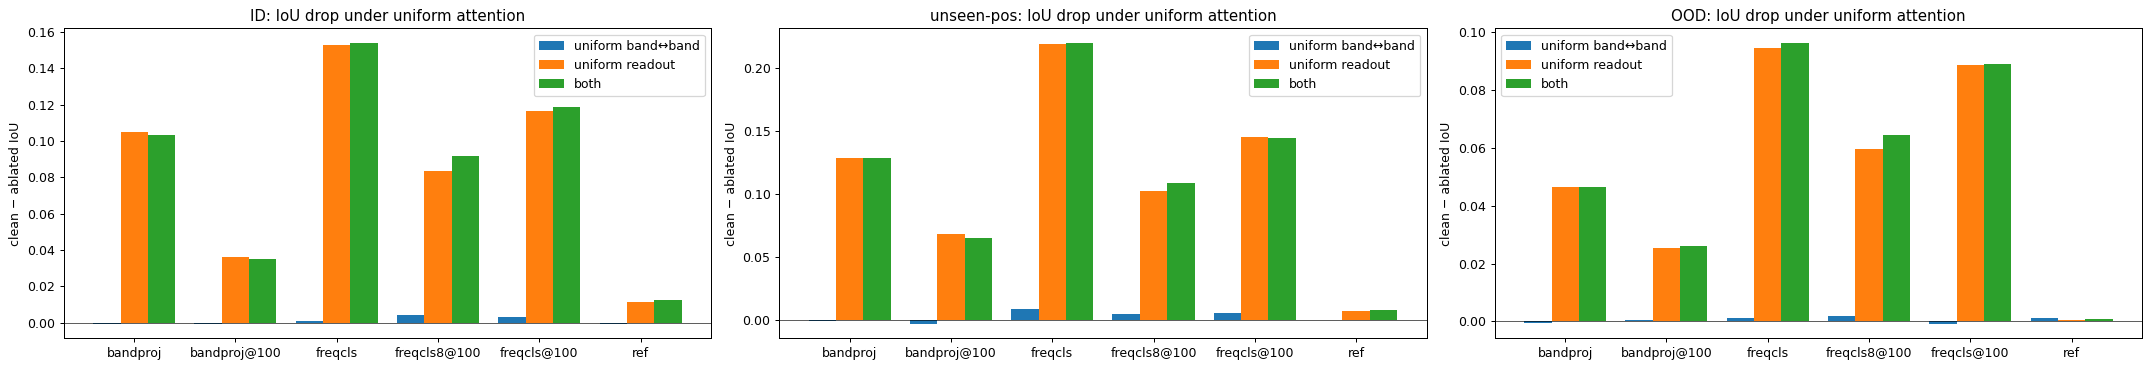

In [19]:
SETS = {"ID": (X, BOX, ID, Y), "unseen-pos": (X, BOX, G["unseen-position"], Y), "OOD": (XO, BO, np.arange(len(YO)), YO)}
iou_of = lambda P, YY, idx: np.mean([((P[j] > THR) & (YY[i] > .5)).sum() / max(((P[j] > THR) | (YY[i] > .5)).sum(), 1) for j, i in enumerate(idx)])
U = {}
for name, m in MF.items():
    for mode, kw in [("clean", {}), ("uniform band↔band", dict(uni_band=True)), ("uniform readout", dict(uni_read=True)), ("both", dict(uni_band=True, uni_read=True))]:
        for s_, (xs, bs_, idx, YY) in SETS.items(): U[(name, mode, s_)] = iou_of(frun(m, xs, bs_, idx, **kw)["mask"].numpy(), YY, idx)
U = pd.Series(U).unstack([1, 2])
drop = pd.concat({mode: U["clean"] - U[mode] for mode in ["uniform band↔band", "uniform readout", "both"]}, axis=1)
display(U["clean"].round(3).rename(columns=lambda c: f"clean {c}")); display(drop.round(3))
fig, axs = plt.subplots(1, 3, figsize=(24, 4.2))
for ax, s_ in zip(axs, SETS):
    v = drop.xs(s_, axis=1, level=1); x = np.arange(len(v)); w = .27
    for i, mode in enumerate(v.columns): ax.bar(x + (i - 1) * w, v[mode], w, label=mode)
    ax.set_xticks(x, v.index); ax.axhline(0, color="k", lw=.5); ax.set(title=f"{s_}: IoU drop under uniform attention", ylabel="clean − ablated IoU"); ax.legend()
plt.tight_layout(); plt.show()

### F2 · attention entropy, sharpness and per-head patterns
Over the 300 ID samples × 100 lasers. Per (model, layer, head): **band→band** = the 18 band query rows, **cls→all** = the `[cls]` row. Entropy
normalized by log T (1 = uniform), max weight (uniform = 1/T), and **sample share** = the share of the attention's variation that is per
(sample, laser) rather than the fixed mean pattern: mean_entries Var(a) / (mean_entries Var(a) + Var_entries(mean a)).

band→band entropy  band→band max w  band→band sample share  cls entropy  cls max w  cls sample share
model        layer                                                                                                      
ref          0                  0.989            0.084                   0.992          NaN        NaN               NaN
             1                  0.979            0.094                   0.985          NaN        NaN               NaN
freqcls      0                  0.992            0.079                   0.949        0.973      0.101             0.827
             1                  0.994            0.076                   0.963        0.968      0.114             0.910
bandproj     0                  0.993            0.079                   0.831        0.983      0.092             0.902
             1                  0.992            0.082                   0.936        0.957      0.135             0.889
freqcls@100  0                  0.992            0.079                   0.942        0.970      0.103             0.848
             1                  0.994            0.076                   0.964        0.967      0.117             0.899
bandproj@100 0                  0.993            0.079                   0.831        0.980      0.094             0.899
             1                  0.992            0.082                   0.934        0.958      0.134             0.892
freqcls8@100 0                  0.991            0.081                   0.948        0.973      0.102             0.918
             1                  0.993            0.078                   0.923        0.972      0.102             0.940
             2                  0.987            0.084                   0.953        0.955      0.122             0.959
             3                  0.977            0.096                   0.982        0.956      0.121             0.969
             4                  0.978            0.096                   0.967        0.968      0.107             0.965
             5                  0.987            0.086                   0.947        0.967      0.115             0.832
             6                  0.988            0.084                   0.969        0.969      0.106             0.960
             7                  0.992            0.079                   0.967        0.983      0.090             0.990

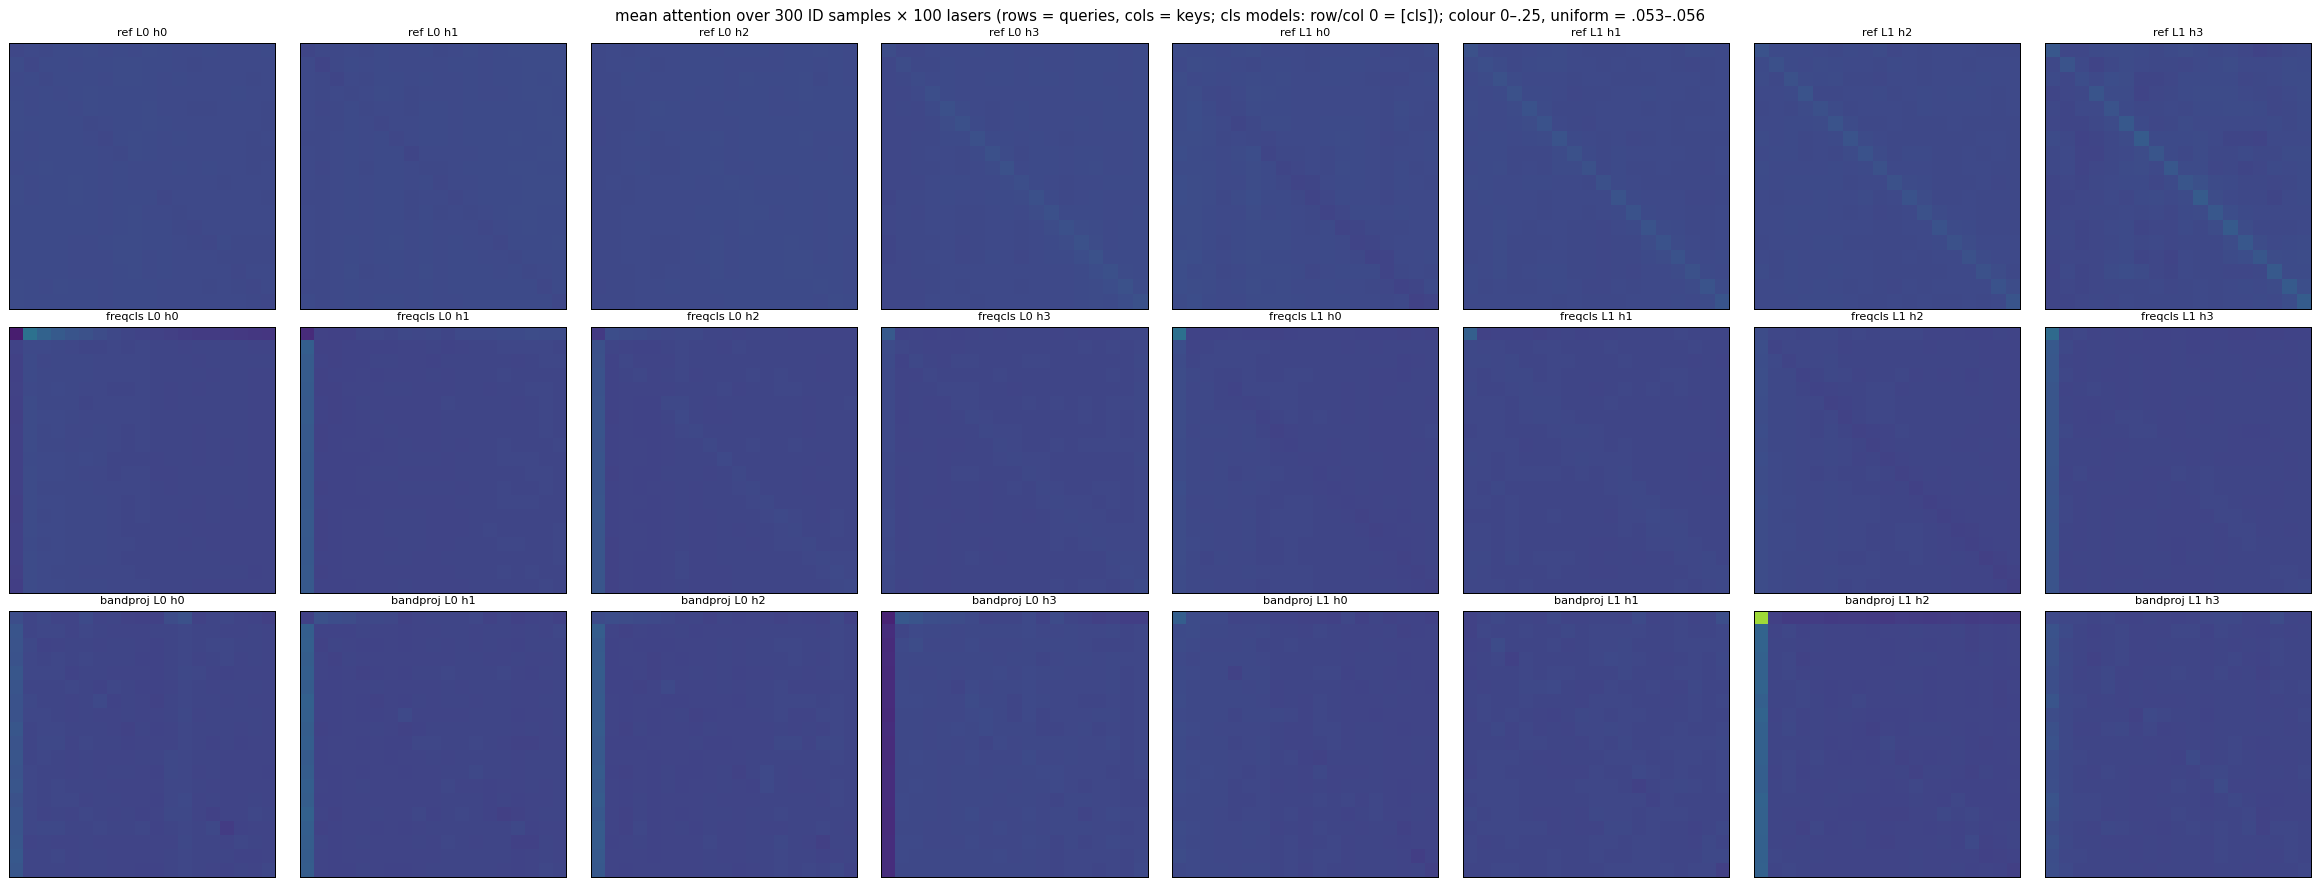

In [20]:
AS = {}
for name, m in MF.items():
    st = {}
    for i in range(0, len(ID), 25): fwd(m, X[ID[i:i + 25]], BOX[ID[i:i + 25]].to(DEV), stats=st)
    AS[name] = st
rows = {}
for name, st in AS.items():
    c = int(bool(MF[name].encoder.freq_enc.cls))
    for l, s in st.items():
        mean, var = (s["sum"] / s["n"]).cpu(), (s["sq"] / s["n"] - (s["sum"] / s["n"]) ** 2).cpu(); ent, mx = (s["ent"] / s["n"]).cpu(), (s["mx"] / s["n"]).cpu()
        for h in range(mean.shape[0]):
            bb = slice(c, None)
            sv, pv = var[h, bb].mean().item(), mean[h, bb].var().item()
            r = {"band→band entropy": ent[h, bb].mean().item(), "band→band max w": mx[h, bb].mean().item(), "band→band sample share": sv / (sv + pv)}
            if c: sv, pv = var[h, 0].mean().item(), mean[h, 0].var().item(); r |= {"cls entropy": ent[h, 0].item(), "cls max w": mx[h, 0].item(), "cls sample share": sv / (sv + pv)}
            rows[(name, l, h)] = r
F2 = pd.DataFrame(rows).T; F2.index.names = ["model", "layer", "head"]
display(F2.groupby(["model", "layer"], sort=False).mean().round(3))
fig, axs = plt.subplots(3, 8, figsize=(26, 10))
for i, name in enumerate(RUNS):
    for l in range(2):
        mean = (AS[name][l]["sum"] / AS[name][l]["n"]).cpu()
        for h in range(4):
            ax = axs[i, l * 4 + h]; ax.imshow(mean[h], cmap="viridis", vmin=0, vmax=.25); ax.set_xticks([]); ax.set_yticks([])
            ax.set_title(f"{name} L{l} h{h}", fontsize=9)
plt.suptitle("mean attention over 300 ID samples × 100 lasers (rows = queries, cols = keys; cls models: row/col 0 = [cls]); colour 0–.25, uniform = .053–.056"); plt.tight_layout(); plt.show()

### F3 · where band identity and per-band information are lost, layer by layer
Band tokens after embed (layer 0) and after every block, for the 300 ID samples on 25 lasers (every 4th), each (laser, band)'s mean over samples
removed (so the fixed band embedding cannot give the band away):
* **band-ID accuracy**: a linear classifier (ridge on one-hot) says which of the 18 bands a sample-dependent token came from (chance .056),
* **subspace overlap**: mean over band pairs of ‖U_bᵀU_c‖²/8 between each band's top-8 PCs (1 = the same subspace, ~8/128 = random),
* **eff. rank** of the concatenated 18-band token (sample-dependent part),
* **folding test per layer**: R² of the band-mean token `mean_b h_b^l` (what a uniform pool reads) and of the `[cls]` state, from the full input
  patch vs the band-averaged patch (folded / full ≈ 1 = folded).

band-ID acc  subspace overlap  eff rank (concat)  eff rank (band-mean)  band-mean: R² full  band-mean: folded/full  cls: R² full  cls: folded/full
model        layer                                                                                                                                                    
ref          0            0.066             0.847              4.408                 2.099               0.102                   0.917           NaN               NaN
             1            0.061             0.846             10.027                 2.498               0.213                   0.999           NaN               NaN
             2            0.057             0.843             27.386                 3.410               0.363                   1.012           NaN               NaN
freqcls      0            0.066             0.887              4.805                 2.131               0.114                   0.926           NaN               NaN
             1            0.062             0.880              5.039                 2.169               0.133                   0.935         0.249             0.964
             2            0.061             0.876              4.858                 2.169               0.153                   0.940         0.403             0.966
bandproj     0            0.258             0.292              5.982                 2.161               0.099                   0.011           NaN               NaN
             1            0.251             0.293              6.071                 2.182               0.113                   0.029         0.271             0.154
             2            0.248             0.295              6.009                 2.212               0.134                   0.060         0.446             0.190
freqcls@100  0            0.066             0.892              4.892                 2.146               0.120                   0.932           NaN               NaN
             1            0.061             0.889              5.097                 2.183               0.139                   0.940         0.273             0.964
             2            0.060             0.886              4.913                 2.183               0.157                   0.945         0.434             0.965
bandproj@100 0            0.258             0.292              5.940                 2.158               0.098                   0.009           NaN               NaN
             1            0.251             0.294              6.011                 2.178               0.112                   0.029         0.273             0.164
             2            0.247             0.295              5.970                 2.209               0.132                   0.064         0.460             0.202
freqcls8@100 0            0.066             0.879              5.050                 2.159               0.123                   0.933           NaN               NaN
             1            0.061             0.878              5.622                 2.214               0.147                   0.944         0.175             0.938
             2            0.058             0.876              6.126                 2.263               0.174                   0.953         0.224             0.954
             3            0.057             0.872              6.662                 2.335               0.183                   1.007         0.250             0.953
             4            0.058             0.856              7.214                 2.452               0.194                   1.000         0.286             0.957
             5            0.056             0.852              7.648                 2.523               0.198                   1.005         0.326             0.966
             6            0.056             0.848              7.837                 2.594               0.201                   1.015         0.382             0.960
            

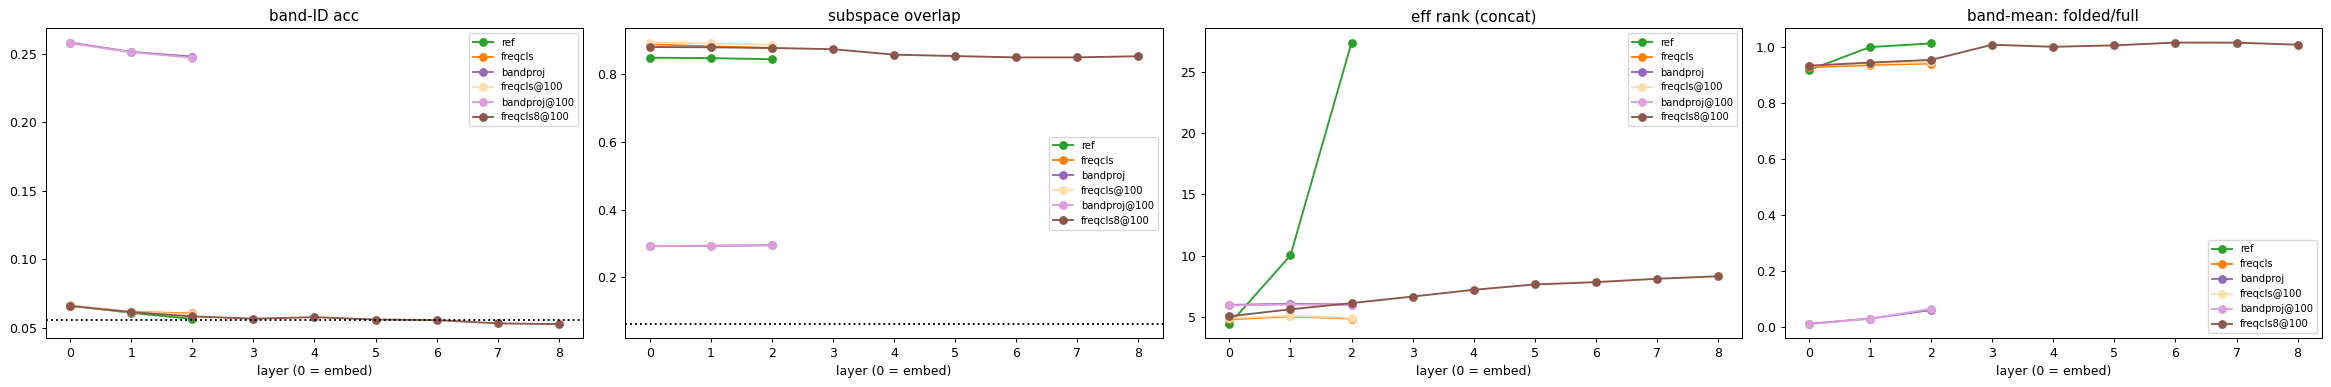

In [21]:
LS = list(range(0, 100, 4)); S3 = len(ID)
def probe_l(Xf, Yf, S, nl, lams=(1e-3, 1e-2, 1e-1, 1)):
    n, v = int(S * .8) * nl, int(S * .6) * nl
    lam = max(lams, key=lambda l: ridge(Xf[:v], Yf[:v], Xf[v:n], Yf[v:n], l).mean().item())
    return ridge(Xf[:n], Yf[:n], Xf[n:], Yf[n:], lam)
def ctr(T): T = T.float(); return T - T.mean(0, keepdim=True)
xs3 = M["ref"].encoder.normalize(X[ID], BOX[ID].to(DEV))[:, LS].reshape(S3, len(LS), 18, 65, 2).cpu()
full3, fold3 = ctr(xs3.flatten(2)).flatten(0, 1), ctr(xs3.mean(2).flatten(2)).flatten(0, 1)
en3 = ctr(xs3.mean((-1, -2))).flatten(0, 1)
pw3 = xs3.pow(2).sum(-1)
nl3 = ctr(torch.cat([xs3.flatten(-2).std(-1), xs3.flatten(-2).amax(-1), (pw3 * torch.arange(65.)).sum(-1) / pw3.sum(-1)], -1)).flatten(0, 1)
del xs3, pw3
def band_id_acc(H):
    """H (S,nl,18,d) centered -> held-out accuracy of a linear band classifier"""
    S, nl = H.shape[:2]; n = int(S * .8)
    tr, te = H[:n].reshape(-1, H.shape[-1]).to(DEV).double(), H[n:].reshape(-1, H.shape[-1]).to(DEV).double()
    ytr = torch.arange(18, device=DEV).repeat(n * nl); yte = torch.arange(18, device=DEV).repeat((S - n) * nl)
    mu, sd = tr.mean(0), tr.std(0) + 1e-8; A = (tr - mu) / sd
    W = torch.linalg.solve(A.T @ A + 1e-2 * len(A) * torch.eye(A.shape[1], device=DEV, dtype=torch.float64), A.T @ F.one_hot(ytr, 18).double())
    return ((((te - mu) / sd) @ W).argmax(1) == yte).float().mean().item()
def overlap(H, k=8):
    Us = [torch.linalg.svd(H[:, :, b].flatten(0, 1).to(DEV).double(), full_matrices=False)[2][:k] for b in range(18)]
    return np.mean([(Us[b] @ Us[c].T).pow(2).sum().item() / k for b in range(18) for c in range(18) if b != c])
def eff_rank(Z): sv = torch.linalg.svdvals(Z.to(DEV).double()) ** 2; return (sv.sum() ** 2 / (sv ** 2).sum()).item()
L3, KEEP = {}, {}
for name, m in MF.items():
    o = frun(m, X, BOX, ID, keep=LS)
    for l, (H, Cs) in enumerate(zip(o["H"], o["C"])):
        Hc = ctr(H)
        r = {"band-ID acc": band_id_acc(Hc), "subspace overlap": overlap(Hc), "eff rank (concat)": eff_rank(Hc.flatten(2).flatten(0, 1)),
             "eff rank (band-mean)": eff_rank(Hc.mean(2).flatten(0, 1))}
        hm = Hc.mean(2).flatten(0, 1)
        f_, a_ = probe_l(full3, hm, S3, len(LS)).mean().item(), probe_l(fold3, hm, S3, len(LS)).mean().item()
        r |= {"band-mean: R² full": f_, "band-mean: folded/full": a_ / f_}
        if Cs is not None:
            cc = ctr(Cs).flatten(0, 1); f_, a_ = probe_l(full3, cc, S3, len(LS)).mean().item(), probe_l(fold3, cc, S3, len(LS)).mean().item()
            r |= {"cls: R² full": f_, "cls: folded/full": a_ / f_}
        L3[(name, l)] = r
    KEEP[name] = dict(H=ctr(o["H"][-1]).flatten(0, 1).flatten(1), tok=ctr(o["raw"][:, LS]).flatten(0, 1))     # last-layer band tokens (concat) and the readout token
    del o
L3 = pd.DataFrame(L3).T; L3.index.names = ["model", "layer"]
display(L3.round(3))
fig, axs = plt.subplots(1, 4, figsize=(26, 4.4))
for name in MF:
    d = L3.loc[name]
    for ax, col in zip(axs, ["band-ID acc", "subspace overlap", "eff rank (concat)", "band-mean: folded/full"]):
        ax.plot(d.index, d[col], "o-", color=COL[name], label=name); ax.set(title=col, xlabel="layer (0 = embed)")
axs[0].axhline(1 / 18, color="k", ls=":"); axs[1].axhline(8 / 128, color="k", ls=":")
for ax in axs: ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

### F4 · readout bottleneck vs encoder bottleneck
On each model's **frozen last-layer band tokens**, fit an **oracle untied readout** = ridge on `concat_b h_b` (2304 features ≡ Σ_b W_b h_b), and
compare with the same probe from the model's own per-laser token (cls output; ref: its readout). Targets, per (sample, laser):
(i) per-band input features: band energy (18, linear) and nonlinear std / max / centroid (54); (ii) the **downstream latent**: the ref's per-laser
token (128-d, the representation the ref's decoder path is built on) and the model's own top-16 token PCs as a sanity row.
The mask itself is a per-sample target (one mask, 100 lasers), so it cannot be probed per laser; the ref token stands in for it.
Tokens high and cls low → the readout is the bottleneck (a per-band V / untied readout fixes it). Both low → info is already gone in the layers.

,band energy: oracle (concat h),band energy: own token,band energy: token/oracle,nonlinear per-band: oracle (concat h),nonlinear per-band: own token,nonlinear per-band: token/oracle,ref token: oracle (concat h),ref token: own token,ref token: token/oracle
ref,0.997,0.669,0.672,0.564,0.294,0.521,0.980,1.000,1.021
freqcls,0.999,0.371,0.372,0.500,0.263,0.527,0.962,0.217,0.226
bandproj,0.999,0.603,0.604,0.505,0.311,0.616,0.948,0.540,0.570
freqcls@100,0.999,0.369,0.369,0.499,0.264,0.529,0.962,0.214,0.223
bandproj@100,0.999,0.614,0.615,0.503,0.314,0.624,0.947,0.526,0.555
freqcls8@100,0.997,0.347,0.348,0.599,0.252,0.422,0.966,0.212,0.220


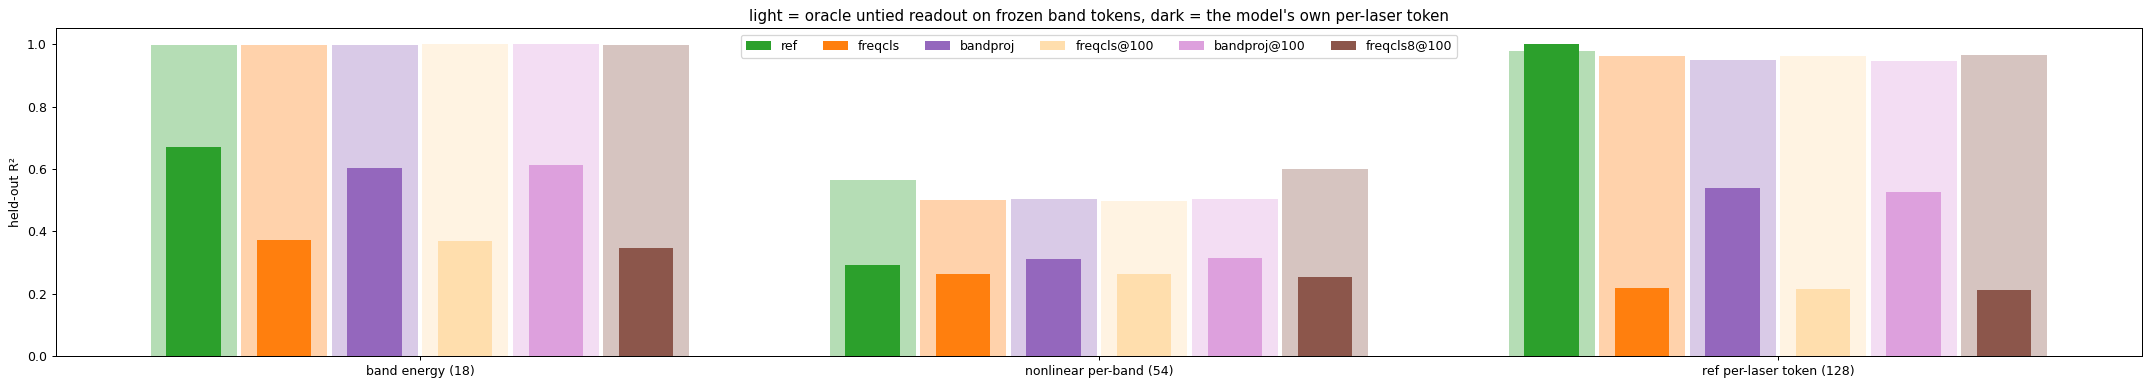

In [22]:
reft = KEEP["ref"]["tok"]
F4 = {}
for name in MF:
    Hc, tok = KEEP[name]["H"], KEEP[name]["tok"]
    r = {}
    for tname, tgt in [("band energy", en3), ("nonlinear per-band", nl3), ("ref token", reft)]:
        a, b = probe_l(Hc, tgt, S3, len(LS)).mean().item(), probe_l(tok, tgt, S3, len(LS)).mean().item()
        r |= {f"{tname}: oracle (concat h)": a, f"{tname}: own token": b, f"{tname}: token/oracle": b / a}
    F4[name] = r
F4 = pd.DataFrame(F4).T; display(F4.round(3))
fig, ax = plt.subplots(figsize=(24, 4.4)); x = np.arange(3); w = .8 / len(MF)
for i, name in enumerate(MF):
    ax.bar(x + i * w - .4 + w / 2, [F4.loc[name, f"{t}: oracle (concat h)"] for t in ["band energy", "nonlinear per-band", "ref token"]], w * .95, color=COL[name], alpha=.35)
    ax.bar(x + i * w - .4 + w / 2, [F4.loc[name, f"{t}: own token"] for t in ["band energy", "nonlinear per-band", "ref token"]], w * .6, color=COL[name], label=name)
ax.set_xticks(x, ["band energy (18)", "nonlinear per-band (54)", "ref per-laser token (128)"]); ax.set(ylabel="held-out R²", title="light = oracle untied readout on frozen band tokens, dark = the model's own per-laser token"); ax.legend(ncol=6)
plt.tight_layout(); plt.show()

### F5 · size: fit vs generalization, depth at matched epochs

In [23]:
fit5 = {}
for name, m in MF.items():
    oo_ = {g: frun(m, X, BOX, ix) for g, ix in G.items()}
    fit5[name] = {**{f"IoU {g}": iou_of(o_["mask"].numpy(), Y, G[g]) for g, o_ in oo_.items()}, **{f"BCE {g}": F.binary_cross_entropy_with_logits(o_["logit"], torch.as_tensor(Y[G[g]])).item() for g, o_ in oo_.items()}}
    del oo_
fit5 = pd.DataFrame(fit5).T; fit5["train − ID IoU"] = fit5["IoU train"] - fit5["IoU id"]; fit5["train BCE / ID BCE"] = fit5["BCE train"] / fit5["BCE id"]
fit5["eff rank last layer (concat)"] = [L3.loc[n].iloc[-1]["eff rank (concat)"] for n in fit5.index]
display(fit5.round(3))
cv = pd.DataFrame({k: {e: i for e, i, _ in CURVE[k]} for k in ["ref", "freqcls", "bandproj", "freqcls8"]}).T
cv["slope 150→200 (ID / 50 ep)"] = cv[200] - cv[150]; cv["slope 100→150"] = cv[150] - cv[100]
display(cv.round(3).rename(columns=lambda c: f"ID@{c}" if isinstance(c, (int, np.integer)) else c))

,IoU train,IoU id,IoU unseen-position,BCE train,BCE id,BCE unseen-position,train − ID IoU,train BCE / ID BCE,eff rank last layer (concat)
ref,0.819,0.685,0.641,0.008,0.032,0.046,0.134,0.265,27.386
freqcls,0.670,0.553,0.542,0.019,0.043,0.049,0.117,0.441,4.858
bandproj,0.720,0.612,0.588,0.014,0.034,0.043,0.108,0.403,6.009
freqcls@100,0.466,0.394,0.367,0.052,0.072,0.092,0.072,0.718,4.913
bandproj@100,0.516,0.449,0.449,0.040,0.057,0.075,0.067,0.706,5.970
freqcls8@100,0.531,0.460,0.431,0.041,0.062,0.074,0.070,0.667,8.318


,ID@50,ID@100,ID@150,ID@200,slope 150→200 (ID / 50 ep),slope 100→150
ref,0.283,0.597,0.670,0.679,0.009,0.073
freqcls,0.066,0.409,0.531,0.562,0.030,0.123
bandproj,0.152,0.456,0.570,0.606,0.036,0.115
freqcls8,0.143,0.467,0.577,NaN,NaN,0.110


**F · reading: which of A / B / C?**
* **F1 uniform attention.** Making band↔band attention uniform costs **nothing** in any model (|ΔIoU| ≤ .008 on ID / unseen-pos / OOD; ref included).
  The Q/K routing between bands is unused. **Untying Q/K per band (C-routing) is pointless.** Making only the `[cls]` readout uniform costs a lot,
  even though its entropy is .96–.98: bandproj −.105 ID / −.129 unseen-pos / −.046 OOD, freqcls −.153 / −.220 / −.095. Setting ref's gate to 1 costs only
  −.011 / −.007 / .000. The cls relies on small, sample-dependent re-weightings (cls sample share .89–.90), and that is all it has to tell bands
  apart through one shared V.
* **F2.** All band→band attention is near uniform (entropy .98–.99, max w ≈ .08) in every model, freqcls8 included. Depth does not sharpen it.
* **F3 layer by layer.** With `W_x^b`, bands are distinguishable after embedding (band-ID accuracy .26 vs chance .056, subspace overlap .29 vs
  .85–.89 for shared embeds) and this stays flat through both layers, so the layers do not erase band identity. What separates ref is that its
  band tokens become **richer with depth**: the concat eff. rank goes 4.4 → 10 → 27 in ref, but stays ≈ 6 in bandproj and ≈ 5 in freqcls (freqcls8
  grows only to 8.3 over 8 layers). The ref's untied readout seems to drive the layers to learn more per-band features; a shared-V cls does not.
* **F4 oracle untied readout on the frozen layer-2 band tokens (the decisive test).** From bandproj's tokens a ridge Σ_b W_b h_b recovers the
  **ref's per-laser token at R² .95** (freqcls .96, freqcls8 .97). Band energy recovers at .999 and nonlinear per-band features at .51. From
  bandproj's own cls token: .54 / .60 / .31 (freqcls .22 / .37 / .26). **Tokens ≫ cls**: the information is in the layers, and **the readout is the bottleneck.**
* **F5 size.** Train IoU (eval mode) ref .82 / bandproj .72 / freqcls .67, train − ID .13 / .11 / .12. This is a **fit gap, not a generalization
  gap**. At matched ep100, freqcls8 (+6 blocks, +1.2M params) gets .460 ID vs freqcls .394 and bandproj .449. Depth helps about as much as `band_proj`,
  but its cls still reads the ref token at only R² .21. The extra layers do not fix the readout.

**Verdict: per-band V / an untied readout at the `[cls]`** (C-content at the readout) is supported (F1b, F4). **Per-band weights in every layer** (A) is
not: band identity already survives the layers (F3), and the tokens already hold ref's information (F4). **Bigger / deeper** (B) gives a
partial, slower gain that leaves the readout bottleneck in place (F4, F5). It is secondary at best. **Untying Q/K** is ruled out (F1a).

## E · conclusion, and the fixes ranked
**Why bandproj < ref.** `band_proj` fixed the input-level band folding of `freq_cls` (+.045 ID). The remaining .073 ID / .033 OOD gap is a
**fit gap** (train IoU .72 vs .82, still climbing +.036 per 50 ep at ep200 vs +.009 for ref). It shows up as diffuse, over-painted masks spread
evenly over splits, objects and positions, mostly in shape rather than location. The layer-2 band tokens hold what the ref needs: an oracle
untied readout recovers the ref's per-laser token at R² .95, while bandproj's own `[cls]` gets only .54. So the **`[cls]` readout (one shared
V, ~uniform attention) is the bottleneck**. It also seems to hold back what the layers learn (token rank ≈ 6 vs 27 in ref). Band↔band routing is unused in every model.

**Ranked fixes** (200 ep, same seed and recipe):
1. **Untied per-band readout after attention.** Ablations: `--freq_cls 0 --band_proj 1` (ref readout + W_x^b; flags exist; +0.28M vs ref). Keeping the
   `[cls]`: per-band V in the cls's last block (+0.29M), or cls ⊕ gated flatten into `pool_o` (new flag `--freq_readout cls+concat`, +16k).
2. **Longer training** (`--max_duration 500ep`, 0 params). Expect +.02–.04 ID from the still-rising curve and cls-1k's +.17 over 1000 ep; it does not close the readout gap.
3. **More readout tokens**, k `[cls]` concatenated (new flag `--freq_cls 4`, ≈ +66k). This is a partial fix: each one is still a shared-V average.
4. **More depth** (`--band_proj 1 --freq_cls 1 --freq_layers 4`, ≈ +0.4M). freqcls8@100 ≈ bandproj@100, and its readout is still the bottleneck (F4).
5. Not useful: untying Q/K per band (uniform band↔band attention costs 0), and per-band weights in every layer (band identity already survives the layers).
6. Caveat: at each run's best threshold (0.3) the ID gap is .061 rather than .072. This is a symptom of the under-fit, not a separate cause.